<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/14_IoT_IIoT_Attack_Detection/QSVM_PQC_IoTAnomalyDetection_Lokesh2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QSVM with post-quantum encryption features and BB84 for IoT anomaly detection: Lokesh and Kaulgud (2025) step by step

**Paper.** B. S. Lokesh and N. Kaulgud, *A Hybrid Post Quantum Cryptography and Quantum Machine Learning Framework for Secure IoT Anomaly Detection*, Research Square preprint (Version 1), 18 September 2025. DOI: [10.21203/rs.3.rs-7538381/v1](https://doi.org/10.21203/rs.3.rs-7538381/v1). (The manifest lists the first author as "S." because the PDF file name was built from the preprint header; the authors are Lokesh B. S. and Narasimha Kaulgud.)

**What this notebook does.** The paper builds a three-stage pipeline for IoT anomaly detection: (1) every sensor message is encrypted with **Kyber-512** (a post-quantum key-encapsulation scheme) and the encryption latency, ciphertext size and key-generation time are appended to the flow features; (2) a session key is distributed with a simulated **BB84** quantum-key-distribution channel; (3) a **quantum SVM** (Qiskit `ZZFeatureMap` + quantum kernel) classifies the flows and is compared with a decision tree, an RBF-SVM and XGBoost. The notebook re-implements all three stages on a public IoT data set and tests each claim of the paper that can be tested:

1. **Kyber-512** is implemented in pure Python/NumPy (key generation, encapsulation, decapsulation, with the Kyber-512 parameters and byte sizes), self-tested, and timed on every flow to build the three PQC features.
2. **BB84** is simulated with Qiskit-Aer under depolarising, amplitude-damping and phase-flip noise, and the measured quantum bit error rate (QBER) is compared with theory and with the paper's 11 % threshold.
3. **qSVM** (4-qubit `ZZFeatureMap`, fidelity kernel) against decision tree, SVM, XGBoost and Random Forest, on **identical inputs**, with and without the PQC features, over several seeds, plus a gate-noise study of the quantum kernel and a training-time scaling study.

**How to run.** Open in Google Colab, choose a CPU runtime and *Run all*. `FAST_MODE = True` (default in the configuration cell) finishes in about 15 minutes on a laptop CPU; `FAST_MODE = False` follows the larger budgets documented in the configuration cell. No GPU, no IBM account and no token are needed (the Hugging Face dataset is public; if you ever point `HF_REPO` at a gated mirror, add your own `HF_TOKEN` in Colab *Settings > Secrets*).

**What you get at the end.** The data set explored and plotted (real flows, ground-truth labels, PCA and angle scatter), the actual quantum circuits drawn, the Kyber-512 timing and size table, BB84 QBER curves, the paper's Table 3 recomputed side by side with the paper's numbers, the PQC-feature ablation, the noisy-kernel result, the scaling plot, and a verdict per claim.

> **Read this first: the paper's data are private.** The paper's headline numbers (Table 3, 94.8 % / 91.3 %) come from its own *PQC-IoT* data set (more than 100,000 records from a Raspberry Pi 3 with DHT11/MQ135/touch sensors, 12 traffic classes) that is **not released** (no link or repository in the preprint). This notebook therefore uses the **public BoT-IoT data set**, which the paper itself names (Section 5.5, "1.5 % improvement on the BoT-IoT dataset") and says its own data set is "similar in structure" to. Every number below is a statement about BoT-IoT flows, not about the authors' data.

## The paper in one page

**Problem.** IoT networks are exposed to attackers that may have quantum capabilities. The authors want an anomaly detector whose data path is quantum-resilient: PQC for the messages, QKD for the session key, QML for the classifier.

**Decision.** Normal vs attack (Table 3 reports accuracy, precision, recall, F1 and AUC-ROC, i.e. a binary decision); the data set has 12 classes (3 benign, 9 attacks) such as replay, DoS, injection, MITM.

**Method.**
* *Phase 1, PQC.* For each flow `F_i` the Kyber-512 encryption time `T_i`, ciphertext size `C_i` and key-generation time `K_i` are measured and appended: `F'_i = [F_i | T_i | C_i | K_i]` (Eq. 7).
* *Phase 2, QKD.* BB84 with random bits and bases, sifting (keep matching bases), QBER estimate, abort if QBER exceeds a threshold `tau`, then error correction and privacy amplification (Algorithm 2). Depolarising channel `E_p(rho) = (1-p) rho + p/3 (X rho X + Y rho Y + Z rho Z)`. A key is usable while QBER is below about 11 %.
* *Phase 3, qSVM.* `ZZFeatureMap` (3 features and 2 repetitions are drawn in Figs. 3 and 5), kernel `K(x, x') = |<phi(x)|phi(x')>|^2` (Eq. 4), classical soft-margin SVM on the kernel matrix, Qiskit Machine Learning on the Aer simulator, 80:20 stratified split, five independent runs.

**Data.** Private PQC-IoT data set (> 100,000 records, 30+ features, 12 classes, CICFlowMeter-style flow features plus PQC metadata). Filtering by variance and correlation thresholds and normalisation (Section 3.1).

**Claims that this notebook can test.**
* C1 Table 3 (PQC-IoT): Decision Tree 92.3 / SVM-RBF 96.1 / XGBoost 96.8 / **qSVM 97.6** accuracy; qSVM P 96.9, R 97.8, F1 97.3, AUC 98.0.
* C2 qSVM is the best model on every metric of Table 3, and beats SVM by 4 to 7 % (abstract) or 1.5 points on Table 3 / BoT-IoT (Section 5.5).
* C3 Noiseless qSVM 94.8 %, under noise 91.3 % (Section 5.4).
* C4 The PQC features add discriminative power (Section 5.7, Fig. 9).
* C5 Five runs, variance below 0.5 % (Section 5.6).
* C6 BB84 QBER stays below 11 % under depolarising, amplitude-damping and phase-flip noise (Section 5.2).
* C7 Kyber-512 encryption takes 4.2 ms per message on a Raspberry Pi 3 (Section 5.3); PQC overhead is 5 to 7 % (Section 5.6).
* C8 Classical SVM training time grows about linearly, qSVM quadratically (Fig. 10).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data set | **private** PQC-IoT: Raspberry Pi 3 sensors, > 100,000 records, 12 classes (9 attack, 3 benign) | **public BoT-IoT** (Koroniotis et al.), Hugging Face mirror `masoltani/bot-iot`, first parquet row group (1,048,576 flows). Binary task normal vs attack, attack half spread evenly over the 10 BoT-IoT attack sub-categories; `# CHOICE:` |
| Flow features | CICFlowMeter-style, "30+" | the **34** per-flow and per-host statistics that BoT-IoT provides (identifiers `stime`, `ltime`, `seq` and all label columns dropped) |
| Sensor message `S_i` and size `M_i` | DHT11/MQ135 readings | BoT-IoT has no payload. `# CHOICE:` the encrypted message is `M_i = clip(sbytes + dbytes, 16, 1024)` bytes of content derived from the flow record; only its length matters for the PQC cost |
| Kyber-512 | `liboqs` / `oqs-python` (C library) | **own pure Python/NumPy implementation** with Kyber-512 round-3 parameters (k=2, q=3329, eta1=3, eta2=2, du=10, dv=4), Fujisaki-Okamoto transform, self-tested; polynomials multiplied by schoolbook convolution instead of NTT, so it is not bit-compatible with liboqs and not constant-time. The session key then drives AES-256-GCM (the paper does not say which cipher carries the data) |
| PQC features | `T_i`, `C_i`, `K_i` (Eq. 7) | the same three, **measured on this machine** (so they are wall-clock numbers and change from run to run) |
| BB84 | custom NumPy module (Sec. 3.2) and Qiskit 1.0 (Sec. 5.2) | both: Qiskit-Aer circuits with the three noise models of Sec. 5.2, plus a NumPy cross-check and an intercept-resend eavesdropper. Noise strengths are not given in the paper; a sweep is shown |
| Feature map / kernel | `ZZFeatureMap`, 3 features drawn, reps 2, `QuantumKernel` (old API) | `zz_feature_map(4, reps=2, entanglement="linear")`, `FidelityStatevectorKernel` / hand-made Gram matrix checked with `np.allclose` (`N_QUBITS = 4`: the paper does not state the qubit count; `# CHOICE:`) |
| Dimensionality reduction | none stated (PCA only mentioned as future work) | required to fit 34+3 features on 4 qubits: variance and correlation filter (as in Sec. 3.1) -> `StandardScaler` -> `PCA(4)` -> `MinMaxScaler((0, pi))`, all fitted on the training split only |
| Bandwidth, SVM `C` | not given | angle scale and `C` chosen on a validation split of the training data (`# CHOICE:`) |
| Split, runs | 80:20 stratified, five runs | 80:20 stratified, `SEEDS` (3 in FAST, 5 in full) |
| Classical baselines | Decision Tree, SVM (RBF), XGBoost; settings not given | same three plus Random Forest on the **same 4 angles** the qSVM sees, and again on **all** filtered features; SVM `C` and `gamma` tuned on the same validation split as the qSVM (so the quantum model gets no tuning advantage) |
| Noise | "noiseless / noisy backend", model not given | Aer density-matrix simulation with depolarising error (`p1 = 0.1 %` on `u`, `p2 = 1 %` on `cx`) on a reduced sample, because every kernel entry is one noisy circuit; `# CHOICE:` |
| Energy, Raspberry Pi timings, QKD hardware | reported | **cannot be checked** here (no Raspberry Pi, no power meter) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and cryptography.
# The pip line runs on Colab (or wherever Qiskit is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" pylatexenc pyarrow huggingface_hub xgboost cryptography
print("setup done (if Colab asks you to restart the session, do so and run all cells again)")

setup done (if Colab asks you to restart the session, do so and run all cells again)


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False            # True: class demo in about 15 minutes. False: 5 seeds, 1000 flows per class, bigger noise and BB84 budgets (about 1 h on a laptop CPU).

SEED   = 42                 # master seed
SEEDS  = [42, 43, 44] if FAST_MODE else [42, 43, 44, 45, 46]   # paper: five independent runs
N_QUBITS    = 4             # CHOICE: the paper draws 3 features but the data have 34+3; 4 PCA angles = 4 qubits
N_PER_CLASS = 300 if FAST_MODE else 1000     # flows per class (normal / attack); paper: > 100,000 records
TEST_SIZE   = 0.2           # paper: 80:20 stratified split
POOL_CAP    = 3000          # CHOICE: cache at most this many flows per BoT-IoT sub-category (keeps the cache small)

# quantum kernel
ZZ_REPS    = 2              # paper Fig. 5: two repetitions
BANDWIDTHS = [0.25, 0.5, 1.0]   # CHOICE: angle scale of the feature map, picked on a validation split of the training data
C_GRID     = [1.0, 10.0, 100.0]
GAMMA_GRID = [0.1, 0.3, 1.0, 3.0]  # classical RBF-SVM gamma grid (angles in [0, pi])

# PQC (pure Python Kyber-512)
N_PQC_BENCH = 200 if FAST_MODE else 1000     # key-generation / encapsulation / decapsulation timing repetitions

# BB84
BB84_N      = 4000 if FAST_MODE else 20000   # transmitted qubits per noise setting
NOISE_LEVELS = [0.0, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30]   # noise strengths for the sweep

# quantum-kernel noise study (every kernel entry is one noisy circuit)
SHOTS       = 1024
NOISE_TRAIN, NOISE_TEST = (60, 60) if FAST_MODE else (150, 100)
P1_ERR, P2_ERR = 0.001, 0.01      # CHOICE: depolarising error of 1-qubit (u) and 2-qubit (cx) gates

# scaling study (Fig. 10 analogue) and qubit sweep
TIMING_N    = [100, 200, 400, 800] if FAST_MODE else [200, 400, 800, 1600, 2400]
QUBIT_SWEEP = [3, 4, 6]

DATA_DIR  = "qc134_data"    # where the downloaded sample is cached
DATA_PATH = ""              # optional: path to your own copy of the BoT-IoT parquet / csv (same columns)
HF_REPO, HF_FILE = "masoltani/bot-iot", "balanced_dataset.parquet"
IBM_TOKEN = ""              # unused: the paper simulates its circuits, no hardware is needed
print("FAST_MODE =", FAST_MODE, "| seeds", SEEDS, "| flows per class", N_PER_CLASS, "| qubits", N_QUBITS)

FAST_MODE = False | seeds [42, 43, 44, 45, 46] | flows per class 1000 | qubits 4


In [3]:
import os, time, json, hashlib, warnings, itertools
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
import sklearn, qiskit, qiskit_aer, qiskit_machine_learning, xgboost
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.algorithms import QSVC
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, amplitude_damping_error, pauli_error
from qiskit_aer.primitives import SamplerV2 as AerSamplerV2
from cryptography.hazmat.primitives.ciphers.aead import AESGCM

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| sklearn", sklearn.__version__, "| xgboost", xgboost.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

# Hugging Face token: only needed if the data set is ever moved behind a gate (BoT-IoT here is public).
# Never type a token into the notebook: on Colab store it in Settings > Secrets as HF_TOKEN.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

qiskit 2.5.2 | qiskit-aer 0.17.2 | qiskit-machine-learning 0.9.1 | sklearn 1.9.1 | xgboost 3.4.1 | numpy 2.5.4 | pandas 3.0.6


## 1. The data: BoT-IoT flows as a public stand-in for the private PQC-IoT set

The authors' **PQC-IoT** data set is not published, so the closest public data of the same kind is used: **BoT-IoT** (Koroniotis, Moustafa, Sitnikova and Turnbull, UNSW Canberra, 2019), which the paper cites as [11] and compares against in Table 1 and Section 5.5. A BoT-IoT record is a network *flow* (an Argus record) described by 34 numeric statistics: protocol, state and flag codes, ports, packet and byte counts per direction, duration, inter-packet-time statistics, rates, and per-host window counters. Attack types: DoS and DDoS floods over TCP, UDP and HTTP, reconnaissance (service scan, OS fingerprinting) and theft (keylogging, data exfiltration) against a simulated smart-home testbed. That is the same kind of flow table the paper describes (flow duration, packet counts, rates, header statistics) and the same attack families (DoS, injection/theft, reconnaissance).

We read **one parquet row group** (1,048,576 flows, 40 columns) of the Hugging Face mirror, so the full 730 MB file is never downloaded. That row group holds all rare classes (normal, keylogging, exfiltration, OS fingerprint, HTTP flood). The cleaned flows are capped to `POOL_CAP` per sub-category and cached in `DATA_DIR` (a few MB).

In [4]:
BASE_FEATS = ["flgs_number", "proto_number", "sport", "dport", "pkts", "bytes", "state_number", "dur", "mean", "stddev", "sum", "min", "max",
              "spkts", "dpkts", "sbytes", "dbytes", "rate", "srate", "drate", "TnBPSrcIP", "TnBPDstIP", "TnP_PSrcIP", "TnP_PDstIP",
              "TnP_PerProto", "TnP_Per_Dport", "AR_P_Proto_P_SrcIP", "AR_P_Proto_P_DstIP", "N_IN_Conn_P_DstIP", "N_IN_Conn_P_SrcIP",
              "AR_P_Proto_P_Sport", "AR_P_Proto_P_Dport", "Pkts_P_State_P_Protocol_P_DestIP", "Pkts_P_State_P_Protocol_P_SrcIP"]
LABELS = ["attack", "category", "subcategory"]
POOL_CACHE = os.path.join(DATA_DIR, "botiot_pool.parquet")
INFO_CACHE = os.path.join(DATA_DIR, "botiot_info.json")

def load_raw():
    # Return the BoT-IoT row group (all 34 features + labels) as a DataFrame.
    cols = BASE_FEATS + LABELS
    if DATA_PATH and os.path.exists(DATA_PATH):
        return pd.read_parquet(DATA_PATH, columns=cols) if DATA_PATH.endswith(".parquet") else pd.read_csv(DATA_PATH, usecols=cols)
    import pyarrow.parquet as pq
    try:
        from huggingface_hub import HfFileSystem
        fs = HfFileSystem(token=HF_TOKEN)
        with fs.open(f"datasets/{HF_REPO}/{HF_FILE}", "rb") as f:
            return pq.ParquetFile(f).read_row_group(0, columns=cols).to_pandas()
    except Exception as e:                                       # fallback: download the whole file once (about 730 MB)
        print("partial read failed (", str(e)[:80], ") -> downloading the full file")
        from huggingface_hub import hf_hub_download
        p = hf_hub_download(HF_REPO, HF_FILE, repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN)
        out = pq.ParquetFile(p).read_row_group(0, columns=cols).to_pandas()
        os.remove(p)                                             # do not keep a 730 MB file around
        return out

def build_pool():
    if os.path.exists(POOL_CACHE) and os.path.exists(INFO_CACHE):
        return pd.read_parquet(POOL_CACHE), json.load(open(INFO_CACHE))
    raw = load_raw()
    for c in ("category", "subcategory"):
        raw[c] = raw[c].astype(str)
    info = dict(raw_shape=list(raw.shape), raw_columns=list(raw.columns),
                attack=raw["attack"].value_counts().to_dict(), category=raw["category"].value_counts().to_dict(),
                subcategory=raw["subcategory"].value_counts().to_dict())
    df = raw.copy(); del raw
    df[BASE_FEATS] = df[BASE_FEATS].apply(pd.to_numeric, errors="coerce")
    df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=BASE_FEATS)          # +-inf -> NaN -> dropped
    df = df.drop_duplicates(subset=BASE_FEATS + ["attack"])                         # BoT-IoT repeats many flows
    nunique = df[BASE_FEATS].nunique()
    const = nunique[nunique <= 1].index.tolist()
    df = df.drop(columns=const)                                                    # constant columns carry no information
    info["clean_shape"] = list(df.shape); info["constant_dropped"] = const
    info["clean_subcategory"] = df["subcategory"].value_counts().to_dict()
    parts = [g.sample(min(len(g), POOL_CAP), random_state=SEED) for _, g in df.groupby("subcategory")]
    pool = pd.concat(parts).reset_index(drop=True)
    pool.to_parquet(POOL_CACHE); json.dump(info, open(INFO_CACHE, "w"))
    return pool, info

t0 = time.time()
POOL, INFO = build_pool()
FEATS = [c for c in BASE_FEATS if c in POOL.columns]
print("pool", POOL.shape, "| features kept", len(FEATS), "| loaded in %.0f s" % (time.time() - t0))
print("raw row group shape:", INFO["raw_shape"], "| after cleaning:", INFO["clean_shape"], "| constant columns dropped:", INFO["constant_dropped"])

pool (33000, 37) | features kept 34 | loaded in 0 s
raw row group shape: [1048576, 37] | after cleaning: [972836, 37] | constant columns dropped: []


### Cleaning and labels

Following the repository recipe: coerce to numeric, replace +-inf by NaN and drop, drop duplicate flows and constant columns (done in the loader above). The BoT-IoT labels are kept as they are: `attack` (0/1, the binary task of Table 3), `category` (Normal, DoS, DDoS, Reconnaissance, Theft) and `subcategory` (11 values). A **balanced** sample is drawn for each run: `N_PER_CLASS` normal flows and `N_PER_CLASS` attack flows, the attack half spread evenly over the ten attack sub-categories so that the "attack" class is a mixture of all families, not just the largest DDoS floods (`# CHOICE:`; the paper's class balance is not given).

In [5]:
ATTACK_SUBS = sorted(POOL.loc[POOL.attack == 1, "subcategory"].unique())
print("attack sub-categories:", ATTACK_SUBS)

def sample_flows(n_per, seed):
    # Balanced binary sample: n_per normal flows + n_per attack flows spread evenly over the attack sub-categories.
    nor = POOL[POOL.attack == 0].sample(n_per, random_state=seed)
    att = POOL[POOL.attack == 1]
    k = int(np.ceil(n_per / len(ATTACK_SUBS)))
    a = pd.concat([att[att.subcategory == s].sample(min(k, int((att.subcategory == s).sum())), random_state=seed) for s in ATTACK_SUBS])
    a = a.sample(n_per, random_state=seed)
    return pd.concat([nor, a]).sample(frac=1, random_state=seed).reset_index(drop=True)

demo = sample_flows(N_PER_CLASS, SEED)
print("sample for seed %d:" % SEED, demo.shape)
print(demo["category"].value_counts().to_dict())

attack sub-categories: ['D-H', 'D-T', 'D-U', 'DD-H', 'DD-T', 'DD-U', 'Data_Exfiltration', 'Keylogging', 'OS_Fingerprint', 'Service_Scan']


sample for seed 42: (2000, 37)
{'Normal': 1000, 'DDoS': 300, 'DoS': 300, 'Theft': 200, 'Reconnaissance': 200}


## 2. Phase 1: post-quantum encryption of every message (Kyber-512, from scratch)

The paper calls `liboqs`/`oqs-python` (a C library that cannot be installed on a stock Colab runtime without system packages). Here Kyber-512 is **implemented in about 80 lines of Python/NumPy** so that the notebook is self-contained. It follows the round-3 specification of CRYSTALS-Kyber for the pieces that matter for sizes, timings and correctness:

* Module-LWE with k = 2 polynomials of degree 256 over `Z_3329[x]/(x^256+1)`, centred-binomial noise (eta1 = 3, eta2 = 2), ciphertext compression (du = 10, dv = 4).
* CPA-secure public-key encryption, wrapped by the **Fujisaki-Okamoto transform** into a CCA2 KEM (`kem_keygen`, `kem_encaps`, `kem_decaps`, implicit rejection).
* Byte sizes must equal the Kyber-512 standard: public key 800, secret key 1,632, ciphertext 768 bytes. They are asserted below.

Differences from `liboqs` (stated so nobody mistakes this for a production library): polynomial products use `np.convolve` (schoolbook) instead of the NTT, so the matrix `A` is sampled in the normal domain and outputs are not bit-identical to the reference implementation; timing is not constant-time. The mathematics (and hence ciphertext size and success of decryption) is the same.

The KEM only transports a 32-byte key. As in any hybrid scheme, that key drives an authenticated cipher for the message itself: **AES-256-GCM** (`# CHOICE:` the paper does not name a data cipher). The paper's per-message quantities are measured as

* `T_i` = time of `kem_encaps` + AES-GCM encryption of the message (ms), the "encryption latency";
* `C_i` = total ciphertext size = 768 (KEM) + 12 (nonce) + message + 16 (tag) bytes;
* `K_i` = time of `kem_keygen` (ms).

In [6]:
Q, N, K_, ETA1, ETA2, DU, DV = 3329, 256, 2, 3, 2, 10, 4   # Kyber-512 (round-3) parameters

def _polymul(a, b):
    c = np.convolve(a, b)                 # schoolbook product, degree <= 510 (int64: max 256*3328^2 ~ 2.8e9)
    r = c[:N].copy(); r[:N - 1] -= c[N:]  # reduce modulo x^256 + 1 (negacyclic wrap-around)
    return r % Q

def _matvec(A, v, transpose=False):
    out = []
    for i in range(K_):
        acc = np.zeros(N, dtype=np.int64)
        for j in range(K_):
            acc += _polymul(A[j][i] if transpose else A[i][j], v[j])
        out.append(acc % Q)
    return out

def _xof_matrix(rho):
    A = [[None] * K_ for _ in range(K_)]
    for i in range(K_):
        for j in range(K_):
            stream = hashlib.shake_128(rho + bytes([j, i])).digest(840)
            b = np.frombuffer(stream, dtype=np.uint8).astype(np.int64).reshape(-1, 3)
            d1 = b[:, 0] + 256 * (b[:, 1] & 15)
            d2 = (b[:, 1] >> 4) + 16 * b[:, 2]
            cand = np.stack([d1, d2], axis=1).reshape(-1)       # rejection sampling of 12-bit values < q
            A[i][j] = cand[cand < Q][:N]
            assert len(A[i][j]) == N
    return A

def _cbd(sigma, nonce, eta):
    buf = hashlib.shake_256(sigma + bytes([nonce])).digest(64 * eta)
    bits = np.unpackbits(np.frombuffer(buf, dtype=np.uint8), bitorder="little").astype(np.int64).reshape(N, 2 * eta)
    return (bits[:, :eta].sum(1) - bits[:, eta:].sum(1)) % Q

def _compress(x, d): return (((x.astype(np.int64) << d) + Q // 2) // Q) & ((1 << d) - 1)
def _decompress(y, d): return ((y.astype(np.int64) * Q) + (1 << (d - 1))) >> d

def _pack(x, d):
    bits = ((x[:, None] >> np.arange(d)) & 1).astype(np.uint8).reshape(-1)
    return np.packbits(bits, bitorder="little").tobytes()
def _unpack(b, d):
    bits = np.unpackbits(np.frombuffer(b, dtype=np.uint8), bitorder="little").reshape(-1, d).astype(np.int64)
    return (bits << np.arange(d)).sum(1)

def _G(x): h = hashlib.sha3_512(x).digest(); return h[:32], h[32:]
def _H(x): return hashlib.sha3_256(x).digest()

def _cpa_keygen(d):
    rho, sigma = _G(d)
    A = _xof_matrix(rho)
    s = [_cbd(sigma, i, ETA1) for i in range(K_)]
    e = [_cbd(sigma, K_ + i, ETA1) for i in range(K_)]
    As = _matvec(A, s)
    t = [(As[i] + e[i]) % Q for i in range(K_)]
    return b"".join(_pack(ti, 12) for ti in t) + rho, b"".join(_pack(si, 12) for si in s)

def _cpa_enc(pk, m, coins):
    t = [_unpack(pk[384 * i:384 * (i + 1)], 12) for i in range(K_)]
    A = _xof_matrix(pk[384 * K_:])
    r = [_cbd(coins, i, ETA1) for i in range(K_)]
    e1 = [_cbd(coins, K_ + i, ETA2) for i in range(K_)]
    e2 = _cbd(coins, 2 * K_, ETA2)
    u = [(x + y) % Q for x, y in zip(_matvec(A, r, transpose=True), e1)]
    mpoly = np.unpackbits(np.frombuffer(m, dtype=np.uint8), bitorder="little").astype(np.int64) * ((Q + 1) // 2)
    v = (sum(_polymul(t[i], r[i]) for i in range(K_)) + e2 + mpoly) % Q
    return b"".join(_pack(_compress(ui, DU), DU) for ui in u) + _pack(_compress(v, DV), DV)

def _cpa_dec(sk, c):
    s = [_unpack(sk[384 * i:384 * (i + 1)], 12) for i in range(K_)]
    step = N * DU // 8
    u = [_decompress(_unpack(c[step * i:step * (i + 1)], DU), DU) for i in range(K_)]
    v = _decompress(_unpack(c[step * K_:], DV), DV)
    w = (v - sum(_polymul(s[i], u[i]) for i in range(K_))) % Q
    return np.packbits(_compress(w, 1).astype(np.uint8), bitorder="little").tobytes()

def kem_keygen():
    pk, sk_cpa = _cpa_keygen(os.urandom(32))
    return pk, sk_cpa + pk + _H(pk) + os.urandom(32)

def kem_encaps(pk):
    m = _H(os.urandom(32))
    kbar, coins = _G(m + _H(pk))
    c = _cpa_enc(pk, m, coins)
    return c, hashlib.shake_256(kbar + _H(c)).digest(32)

def kem_decaps(sk, c):
    sk_cpa, pk, h, z = sk[:768], sk[768:768 + 800], sk[768 + 800:768 + 832], sk[768 + 832:]
    m = _cpa_dec(sk_cpa, c)
    kbar, coins = _G(m + h)
    c2 = _cpa_enc(pk, m, coins)
    return hashlib.shake_256((kbar if c2 == c else z) + _H(c)).digest(32)

# ---- self-test: sizes of the Kyber-512 standard, key agreement, implicit rejection of a tampered ciphertext
pk, sk = kem_keygen()
assert (len(pk), len(sk)) == (800, 1632), (len(pk), len(sk))
for _ in range(25):
    ct, key_a = kem_encaps(pk)
    assert len(ct) == 768 and kem_decaps(sk, ct) == key_a
bad = bytearray(ct); bad[5] ^= 1
assert kem_decaps(sk, bytes(bad)) != key_a
print("Kyber-512 self-test passed: pk %d B, sk %d B, ciphertext %d B, 25/25 key agreements, tampered ciphertext rejected" % (len(pk), len(sk), len(ct)))

Kyber-512 self-test passed: pk 800 B, sk 1632 B, ciphertext 768 B, 25/25 key agreements, tampered ciphertext rejected


In [7]:
def time_ms(fn, reps):
    out = []
    for _ in range(reps):
        t0 = time.perf_counter_ns(); r = fn(); out.append((time.perf_counter_ns() - t0) / 1e6)
    return np.array(out), r

t_kg, _ = time_ms(kem_keygen, N_PQC_BENCH)
pk, sk = kem_keygen()
t_en, (ct, key) = time_ms(lambda: kem_encaps(pk), N_PQC_BENCH)
t_de, _ = time_ms(lambda: kem_decaps(sk, ct), N_PQC_BENCH)
msg = os.urandom(512)
def aes_enc():
    n = os.urandom(12); return n + AESGCM(key).encrypt(n, msg, None)
t_ae, _ = time_ms(aes_enc, N_PQC_BENCH)
bench = pd.DataFrame({"operation": ["Kyber-512 key generation", "Kyber-512 encapsulation", "Kyber-512 decapsulation", "AES-256-GCM, 512-byte message"],
                      "mean ms": [x.mean() for x in (t_kg, t_en, t_de, t_ae)], "std ms": [x.std() for x in (t_kg, t_en, t_de, t_ae)],
                      "median ms": [np.median(x) for x in (t_kg, t_en, t_de, t_ae)]}).round(3)
print("this machine, %d repetitions each (paper: 4.2 ms mean encryption per message on a Raspberry Pi 3 with liboqs)" % N_PQC_BENCH)
display(bench)
PQC_ENC_MS_HERE = float(t_en.mean() + t_ae.mean())

this machine, 1000 repetitions each (paper: 4.2 ms mean encryption per message on a Raspberry Pi 3 with liboqs)


,operation,mean ms,std ms,median ms
0,Kyber-512 key generation,3.338,4.304,1.869
1,Kyber-512 encapsulation,4.344,4.767,3.181
2,Kyber-512 decapsulation,4.491,3.064,3.586
3,"AES-256-GCM, 512-byte message",0.012,0.113,0.007


### Appending the PQC features to every flow

BoT-IoT carries no sensor payload, so for each flow the notebook builds a message of `M_i = clip(sbytes + dbytes, 16, 1024)` bytes (content derived from the flow record by SHAKE-256; the content has no influence on the cost, the length has), runs key generation, encapsulation and AES-GCM encryption on it with the real Kyber-512 code above, and records `(T_i, C_i, K_i)`. Every 50th flow also decapsulates and checks that sender and receiver derive the same key. This follows Eq. 7: `F'_i = [F_i || T_i, C_i, K_i]`. Note what it can and cannot do: the three numbers are **measurements of the cryptographic work done on that flow**; on a real testbed they could correlate with an attack (for example a flood of tiny messages), here they depend only on the message length and on machine noise.

In [8]:
PQC_FEATS = ["pqc_enc_ms", "pqc_ct_bytes", "pqc_keygen_ms"]

def add_pqc_features(df):
    out = np.zeros((len(df), 3))
    recs = df[FEATS].values.astype(np.float32)
    sizes = (df["sbytes"].values + df["dbytes"].values) if "sbytes" in df else np.full(len(df), 256)
    for i in range(len(df)):
        M = int(np.clip(sizes[i], 16, 1024))                              # CHOICE: message length tied to the flow's bytes
        message = hashlib.shake_256(recs[i].tobytes()).digest(M)
        t0 = time.perf_counter_ns(); pk_, sk_ = kem_keygen(); t1 = time.perf_counter_ns()
        ct_, key_ = kem_encaps(pk_)
        nonce = os.urandom(12); enc = AESGCM(key_).encrypt(nonce, message, None); t2 = time.perf_counter_ns()
        if i % 50 == 0:
            assert kem_decaps(sk_, ct_) == key_                         # receiver derives the same key
        out[i] = [(t2 - t1) / 1e6, len(ct_) + len(nonce) + len(enc), (t1 - t0) / 1e6]
    res = df.copy()
    for j, c in enumerate(PQC_FEATS):
        res[c] = out[:, j]
    return res

t0 = time.time()
demo = add_pqc_features(demo)
print("PQC features for %d flows in %.1f s (%.2f ms per flow, including the 3 timers)" % (len(demo), time.time() - t0, (time.time() - t0) / len(demo) * 1e3))
display(demo[PQC_FEATS].describe().round(3).T)
display(demo.groupby("attack")[PQC_FEATS].mean().round(3).rename(index={0: "normal", 1: "attack"}))

PQC features for 2000 flows in 10.3 s (5.14 ms per flow, including the 3 timers)


,count,mean,std,min,25%,50%,75%,max
pqc_enc_ms,2000.0,2.859,2.185,1.05,1.844,2.132,2.807,35.869
pqc_ct_bytes,2000.0,1340.762,375.774,856.00,967.000,1276.000,1820.000,1820.000
pqc_keygen_ms,2000.0,2.054,1.715,0.81,1.332,1.533,1.930,31.808


,pqc_enc_ms,pqc_ct_bytes,pqc_keygen_ms
attack,,,
normal,2.837,1264.714,1.996
attack,2.882,1416.811,2.113


## 3. Preprocessing, split and the quantum-ready angles

The paper (Section 3.1) filters features "using variance and correlation thresholds" and normalises "for compatibility with quantum encoding". It never says how 34 to 37 features reach the qubits. The notebook follows the repository pipeline, **every transform fitted on the training split only**:

`signed log1p` (flow statistics span many decades) -> drop constant columns and one of every pair of features with |correlation| > 0.98 (the paper's variance/correlation filter) -> `StandardScaler` -> `PCA(N_QUBITS)` -> `MinMaxScaler((0, pi))`, test angles clipped to `[0, pi]`.

Two feature sets are prepared for each run, exactly as in the paper's comparison: **IoT** = the 34 flow features, and **PQC-IoT** = the same plus `pqc_enc_ms`, `pqc_ct_bytes`, `pqc_keygen_ms`.

In [9]:
VARIANTS = {"IoT": FEATS, "PQC-IoT": FEATS + PQC_FEATS}

def slog(X):
    X = np.asarray(X, dtype=float)
    return np.sign(X) * np.log1p(np.abs(X))

class Prep:
    # variance/correlation filter -> StandardScaler -> PCA(n) -> MinMax(0, pi); everything fitted on the training split
    def __init__(self, n_comp, corr_thr=0.98):
        self.n_comp, self.corr_thr = n_comp, corr_thr
    def fit(self, X):
        L = slog(X)
        keep = np.where(L.var(0) > 1e-10)[0]                                    # variance threshold
        C = np.nan_to_num(np.corrcoef(L[:, keep], rowvar=False))
        sel = []
        for a in range(len(keep)):
            if all(abs(C[a, b]) <= self.corr_thr for b in sel):                 # correlation threshold (greedy)
                sel.append(a)
        self.keep = keep[sel]
        self.sc = StandardScaler().fit(L[:, self.keep])
        Z = self.sc.transform(L[:, self.keep])
        self.pca = PCA(n_components=self.n_comp, random_state=SEED).fit(Z)
        self.mm = MinMaxScaler((0, np.pi)).fit(self.pca.transform(Z))
        return self
    def std(self, X): return self.sc.transform(slog(X)[:, self.keep])           # all filtered features, standardised
    def pca_raw(self, X): return self.pca.transform(self.std(X))                # raw PCA coordinates
    def angles(self, X): return np.clip(self.mm.transform(self.pca_raw(X)), 0, np.pi)

DATA = {}
def get_data(seed, n_per=None, n_comp=None):
    # Balanced sample + PQC features + stratified 80:20 split + one Prep per feature set, all for one seed.
    key = (seed, n_per or N_PER_CLASS, n_comp or N_QUBITS)
    if key in DATA:
        return DATA[key]
    df = add_pqc_features(sample_flows(key[1], seed))
    y = df["attack"].values
    itr, ite = train_test_split(np.arange(len(df)), test_size=TEST_SIZE, stratify=y, random_state=seed)
    d = dict(df=df, y=y, itr=itr, ite=ite, ytr=y[itr], yte=y[ite], P={}, Xtr={}, Xte={})
    for v, cols in VARIANTS.items():
        X = df[cols].values.astype(float)
        d["Xtr"][v], d["Xte"][v] = X[itr], X[ite]
        d["P"][v] = Prep(key[2]).fit(X[itr])
    DATA[key] = d
    return d

S0 = SEEDS[0]
t0 = time.time(); d0 = get_data(S0)
print("seed %d: %d flows, train %d / test %d, built in %.0f s" % (S0, len(d0["df"]), len(d0["itr"]), len(d0["ite"]), time.time() - t0))
for v in VARIANTS:
    P = d0["P"][v]
    print("%-8s: %d features -> %d after variance/correlation filter -> %d PCA components (explained variance %.1f %%)" % (
        v, len(VARIANTS[v]), len(P.keep), P.n_comp, 100 * P.pca.explained_variance_ratio_.sum()))

seed 42: 2000 flows, train 1600 / test 400, built in 10 s
IoT     : 34 features -> 32 after variance/correlation filter -> 4 PCA components (explained variance 67.0 %)
PQC-IoT : 37 features -> 35 after variance/correlation filter -> 4 PCA components (explained variance 63.4 %)


## Dataset Exploration and Visualisation

Everything below shows the **real BoT-IoT flows** and their ground-truth labels (nothing generated). First the shape, the feature names and the original label values with class counts, then the class distributions, then 2-D scatter plots of the real training flows: the first two **raw PCA coordinates** (PCA fitted on the training split) and the same points after the MinMax scaling to **angles in `[0, pi]`** that the 4-qubit feature map receives. Points are coloured by the original BoT-IoT `category` (Normal, DoS, DDoS, Reconnaissance, Theft), so the multi-class attack structure is visible although the task is binary. Finally the three measured PQC features are plotted per class.

In [10]:
print("raw BoT-IoT row group shape (rows, columns):", tuple(INFO["raw_shape"]))
print("columns used as features (%d):" % len(FEATS)); print(FEATS)
print("columns dropped as constant:", INFO["constant_dropped"], "| shape after cleaning:", tuple(INFO["clean_shape"]))
print("\noriginal label values and counts in the row group (before cleaning)")
print("  attack      :", INFO["attack"])
print("  category    :", INFO["category"])
print("  subcategory :", INFO["subcategory"])
print("\npool used for sampling (after cleaning, capped at %d per sub-category):" % POOL_CAP)
print(POOL["subcategory"].value_counts().to_dict())
print("\nbalanced sample of seed %d: train %d / test %d" % (S0, len(d0["itr"]), len(d0["ite"])))
cats = d0["df"].loc[d0["itr"], "category"].value_counts().to_dict(); print("  train category counts:", cats)
display(d0["df"][FEATS + PQC_FEATS + ["subcategory", "category", "attack"]].head(5))

raw BoT-IoT row group shape (rows, columns): (1048576, 37)
columns used as features (34):
['flgs_number', 'proto_number', 'sport', 'dport', 'pkts', 'bytes', 'state_number', 'dur', 'mean', 'stddev', 'sum', 'min', 'max', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'srate', 'drate', 'TnBPSrcIP', 'TnBPDstIP', 'TnP_PSrcIP', 'TnP_PDstIP', 'TnP_PerProto', 'TnP_Per_Dport', 'AR_P_Proto_P_SrcIP', 'AR_P_Proto_P_DstIP', 'N_IN_Conn_P_DstIP', 'N_IN_Conn_P_SrcIP', 'AR_P_Proto_P_Sport', 'AR_P_Proto_P_Dport', 'Pkts_P_State_P_Protocol_P_DestIP', 'Pkts_P_State_P_Protocol_P_SrcIP']
columns dropped as constant: [] | shape after cleaning: (972836, 37)

original label values and counts in the row group (before cleaning)
  attack      : {'1': 1043684, '0': 4892}
  category    : {'DDoS': 542232, 'DoS': 465885, 'Reconnaissance': 25580, 'Theft': 9987, 'Normal': 4892}
  subcategory : {'D-U': 288410, 'DD-T': 273118, 'DD-U': 264238, 'D-T': 172499, 'Service_Scan': 20604, 'Data_Exfiltration': 5029, 'OS_Fingerprint'

,flgs_number,proto_number,sport,dport,pkts,bytes,state_number,dur,mean,stddev,sum,min,max,spkts,dpkts,sbytes,dbytes,rate,srate,drate,TnBPSrcIP,TnBPDstIP,TnP_PSrcIP,TnP_PDstIP,TnP_PerProto,TnP_Per_Dport,AR_P_Proto_P_SrcIP,AR_P_Proto_P_DstIP,N_IN_Conn_P_DstIP,N_IN_Conn_P_SrcIP,AR_P_Proto_P_Sport,AR_P_Proto_P_Dport,Pkts_P_State_P_Protocol_P_DestIP,Pkts_P_State_P_Protocol_P_SrcIP,pqc_enc_ms,pqc_ct_bytes,pqc_keygen_ms,subcategory,category,attack
0,1,1,57542,80,10,1729,1,21.056090,0.002019,0.002856,0.006059,0.000000,0.006059,6,4,963,766,0.427429,0.237461,0.594105,94003,110081,702,775,799,775,0.537860,0.490928,96,89,0.474922,0.490928,755,702,1.6903,1820.0,2.5146,DD-H,DDoS,1
1,1,2,-1,-1,9,549,2,1187.591951,0.000082,0.000025,0.000369,0.000055,0.000123,4,4,274,274,0.006815,0.002970,0.002970,1817,4017,22,56,54,54,0.008214,0.008414,10,7,0.009087,0.009087,50,9,1.7194,1344.0,1.2589,Normal,Normal,0
2,1,1,36682,22,28,5115,6,0.617790,0.617790,0.000000,0.617790,0.617790,0.617790,13,15,1647,3468,52.987057,23.544900,27.481308,40460,39140,259,237,395,215,11.978300,10.867500,8,19,54.947931,10.867500,215,215,2.8610,1820.0,3.1794,Data_Exfiltration,Theft,1
3,1,3,35636,53,2,172,4,2.501086,0.000000,0.000000,0.000000,0.000000,0.000000,2,0,172,0,0.399826,0.399826,0.000000,11304,3096,62,36,123687,93,2.356740,0.799779,18,18,0.799652,1.778060,36,14,2.4319,968.0,1.9217,Normal,Normal,0
4,1,1,46794,106,2,120,1,0.004383,0.004383,0.000000,0.004383,0.004383,0.004383,1,1,60,60,228.154221,0.000000,0.000000,11880,11880,198,198,198,2,521.534000,521.534000,100,100,521.534000,456.308000,196,196,2.5541,916.0,1.1976,Service_Scan,Reconnaissance,1


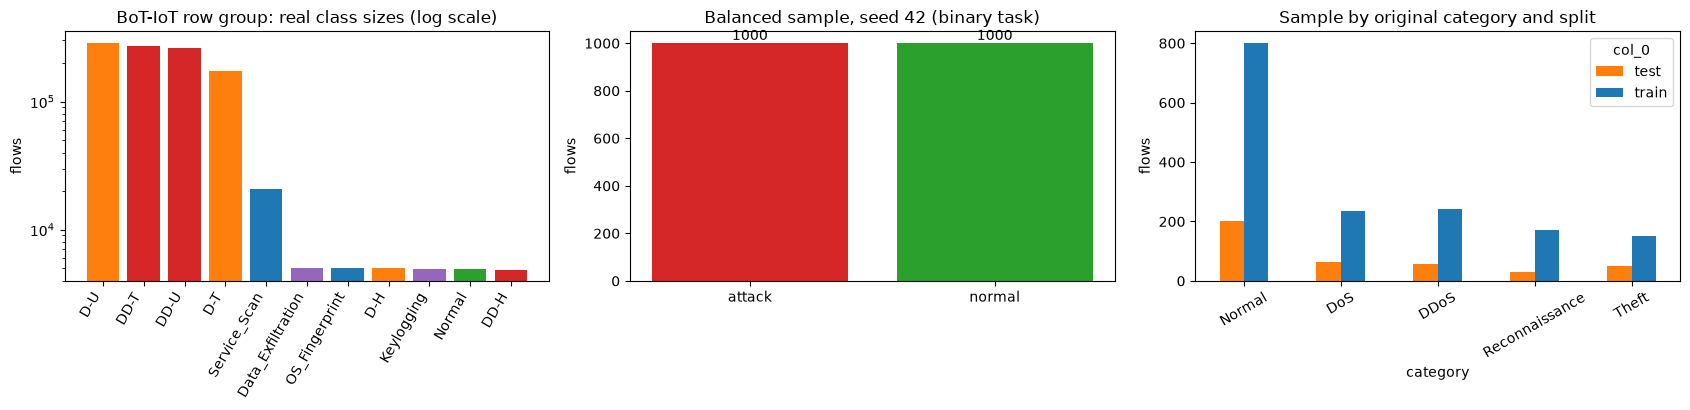

In [11]:
CATS = ["Normal", "DoS", "DDoS", "Reconnaissance", "Theft"]
CPAL = dict(zip(CATS, ["tab:green", "tab:orange", "tab:red", "tab:blue", "tab:purple"]))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
sub = pd.Series(INFO["subcategory"]); catof = POOL.drop_duplicates("subcategory").set_index("subcategory")["category"]
ax[0].bar(range(len(sub)), sub.values, color=[CPAL[catof[s]] for s in sub.index]); ax[0].set_yscale("log")
ax[0].set_xticks(range(len(sub))); ax[0].set_xticklabels(sub.index, rotation=60, ha="right")
ax[0].set_title("BoT-IoT row group: real class sizes (log scale)"); ax[0].set_ylabel("flows")
df0 = d0["df"]
b = df0["attack"].map({0: "normal", 1: "attack"}).value_counts()
ax[1].bar(b.index, b.values, color=["tab:green" if i == "normal" else "tab:red" for i in b.index])
ax[1].set_title("Balanced sample, seed %d (binary task)" % S0); ax[1].set_ylabel("flows")
for i, v in enumerate(b.values): ax[1].text(i, v, str(v), ha="center", va="bottom")
ct = pd.crosstab(df0["category"], np.where(df0.index.isin(d0["itr"]), "train", "test")).reindex(CATS)
ct.plot.bar(ax=ax[2], color=["tab:orange", "tab:blue"], rot=30); ax[2].set_title("Sample by original category and split"); ax[2].set_ylabel("flows")
plt.tight_layout(); plt.show()

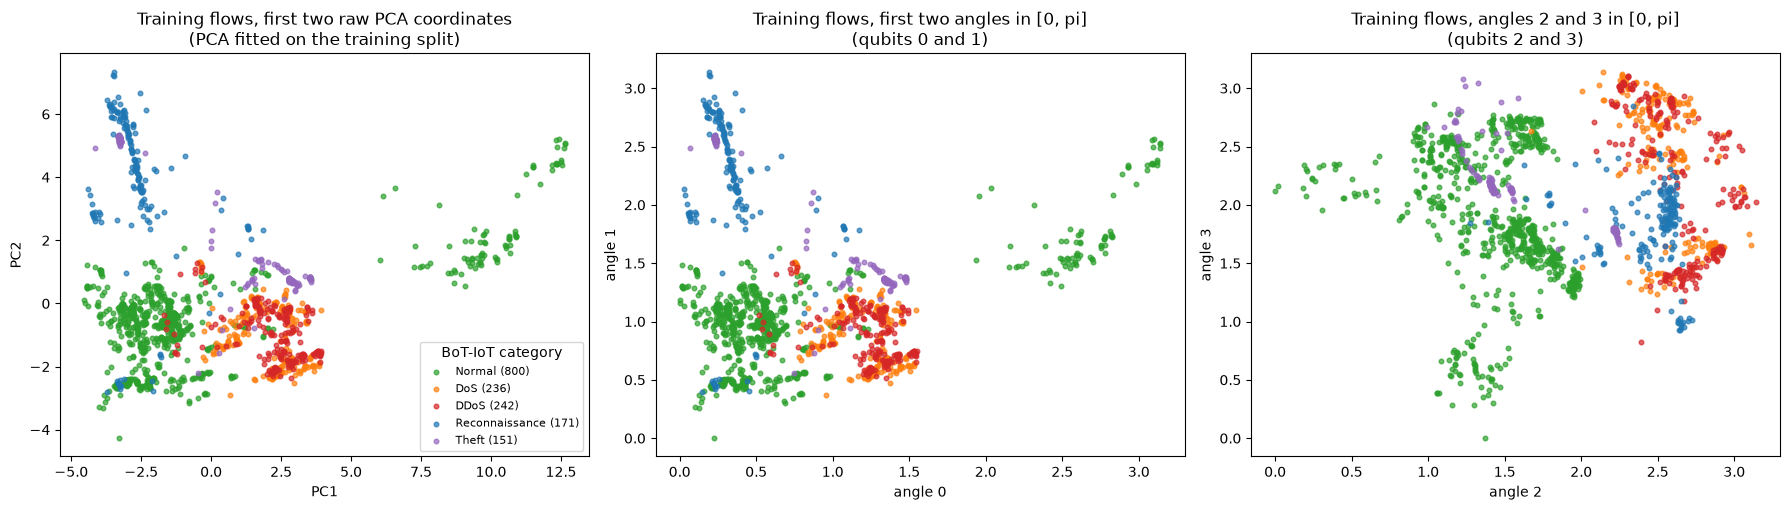

PCA explained variance ratios: [0.325 0.142 0.102 0.065]


In [12]:
P = d0["P"]["PQC-IoT"]; Xtr = d0["Xtr"]["PQC-IoT"]; ctr = d0["df"].loc[d0["itr"], "category"].values
Z = P.pca_raw(Xtr); A = P.angles(Xtr)
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
for c in CATS:
    m = ctr == c
    ax[0].scatter(Z[m, 0], Z[m, 1], s=11, alpha=0.7, color=CPAL[c], label="%s (%d)" % (c, m.sum()))
    ax[1].scatter(A[m, 0], A[m, 1], s=11, alpha=0.7, color=CPAL[c])
    ax[2].scatter(A[m, 2], A[m, 3], s=11, alpha=0.7, color=CPAL[c])
ax[0].set_title("Training flows, first two raw PCA coordinates\n(PCA fitted on the training split)"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2")
ax[1].set_title("Training flows, first two angles in [0, pi]\n(qubits 0 and 1)"); ax[1].set_xlabel("angle 0"); ax[1].set_ylabel("angle 1")
ax[2].set_title("Training flows, angles 2 and 3 in [0, pi]\n(qubits 2 and 3)"); ax[2].set_xlabel("angle 2"); ax[2].set_ylabel("angle 3")
ax[0].legend(title="BoT-IoT category", fontsize=8)
plt.tight_layout(); plt.show()
print("PCA explained variance ratios:", P.pca.explained_variance_ratio_.round(3))

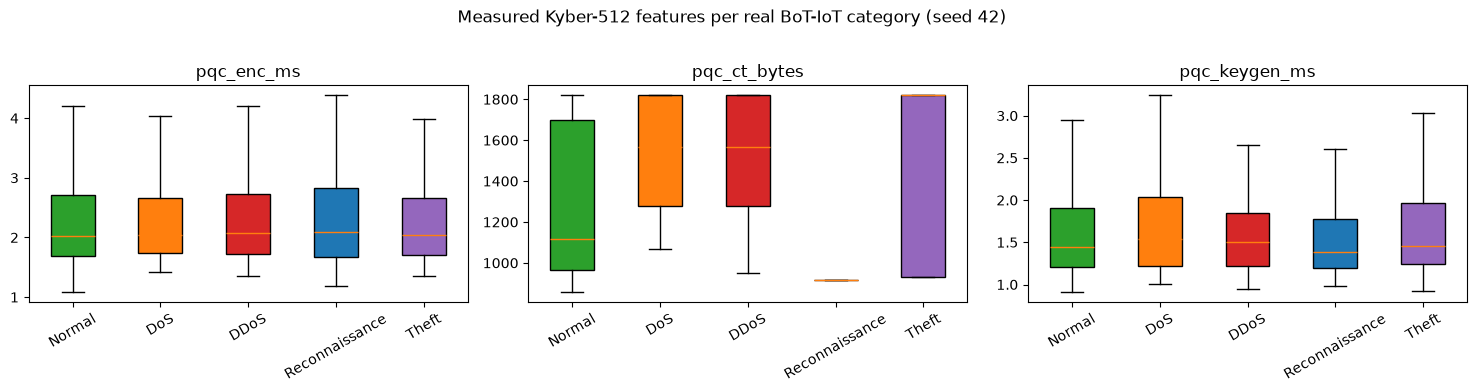

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for j, f in enumerate(PQC_FEATS):
    data = [d0["df"].loc[d0["df"].category == c, f].values for c in CATS]
    bp = ax[j].boxplot(data, patch_artist=True, showfliers=False); ax[j].set_xticklabels(CATS)
    for patch, c in zip(bp["boxes"], CATS): patch.set_facecolor(CPAL[c])
    ax[j].set_title(f); ax[j].tick_params(axis="x", rotation=30)
plt.suptitle("Measured Kyber-512 features per real BoT-IoT category (seed %d)" % S0, y=1.02)
plt.tight_layout(); plt.show()

## 4. Phase 2: BB84 key distribution (Qiskit-Aer, three noise models)

BB84 in one paragraph. Alice draws a random bit and a random basis (rectilinear `Z` or diagonal `X`) for each qubit and prepares `|0>`, `|1>`, `|+>` or `|->` (gates `X` for bit 1, `H` for the diagonal basis). Bob measures each qubit in a random basis (`H` before measurement for the diagonal basis). They publicly compare bases and **keep only the positions where the bases match** (about half, the *sifted key*). Over a noiseless channel the sifted keys are identical; the fraction of disagreeing bits in the sifted key is the **QBER**. An eavesdropper who measures and resends disturbs half of the qubits she measures in the wrong basis and raises the QBER to about 25 %.

**Noise models of Section 5.2.** The channel is a single `id` gate with a noise instruction attached: *depolarising* (`rho -> (1-p) rho + p/3 (X rho X + Y rho Y + Z rho Z)`, the paper's own formula), *amplitude damping* (`gamma`) and *phase flip* (`Z` with probability `p`). The paper does not state the noise strengths, so a sweep is shown. Expected QBER over random matched bases: depolarising `2p/3` (the paper's text writes `p/2`, which does not follow from its own channel: a `Z`-basis measurement is flipped by `X` or `Y`, so the flip probability is `2p/3`), phase flip `p/2` (only the diagonal basis is affected), amplitude damping `(gamma/2 + (1 - sqrt(1-gamma))/2) / 2`.

**Secret-key rate** (paper, Section 3.3): `R = q [1 - h2(Q) - f_EC h2(Q)]` with sifting factor `q = 1/2`. A key can be distilled only while `R > 0`; with perfect error correction `f_EC = 1` this is `Q < 11.0 %`, which is the paper's "11 % threshold".

QBER threshold where the asymptotic key rate reaches 0: f_EC=1.00 -> 11.00 %, f_EC=1.16 -> 9.81 %


BB84 on Qiskit-Aer, 20000 qubits per setting, 16 s


,noise,strength,QBER,se,theory,sifted,QBER<11%,R(f=1)
0,depolarizing,0.00,0.0000,0.0000,0.0000,10104,True,0.5000
1,depolarizing,0.02,0.0161,0.0013,0.0133,10104,True,0.3809
2,depolarizing,0.05,0.0376,0.0019,0.0333,10104,True,0.2688
3,depolarizing,0.10,0.0719,0.0026,0.0667,10104,True,0.1272
4,depolarizing,0.15,0.1046,0.0030,0.1000,10104,True,0.0166
5,depolarizing,0.20,0.1365,0.0034,0.1333,10104,False,0.0000
6,depolarizing,0.30,0.2025,0.0040,0.2000,10104,False,0.0000
7,amplitude damping,0.00,0.0000,0.0000,0.0000,10104,True,0.5000
8,amplitude damping,0.02,0.0100,0.0010,0.0075,10104,True,0.4192
9,amplitude damping,0.05,0.0217,0.0014,0.0188,10104,True,0.3493


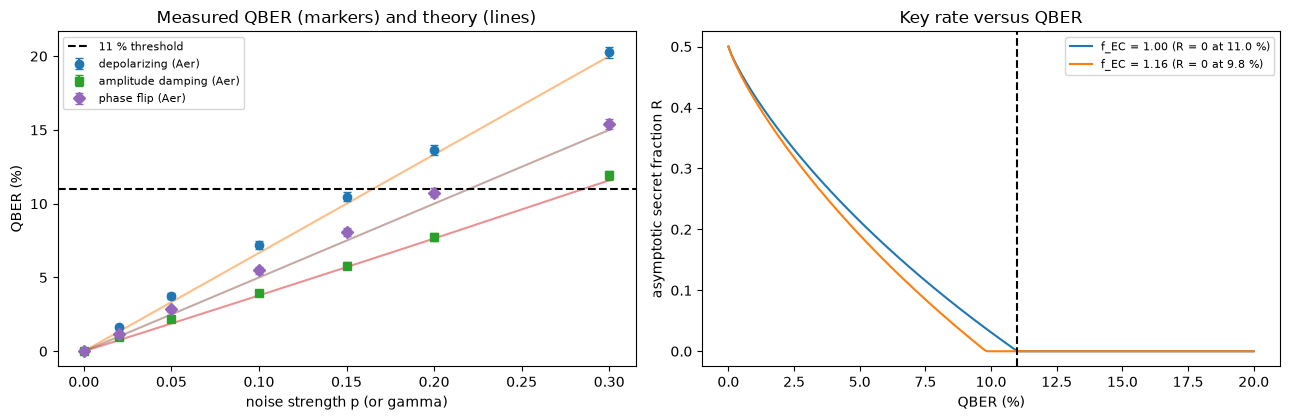

In [14]:
from scipy.optimize import brentq

def bb84_circuit(bit, a_diag, b_diag):
    qc = QuantumCircuit(1, 1, name="BB84")
    if bit: qc.x(0)                 # Alice: encode the bit
    if a_diag: qc.h(0)              # Alice: diagonal basis
    qc.id(0)                        # the quantum channel (noise is attached to this instruction)
    if b_diag: qc.h(0)              # Bob: measure in the diagonal basis
    qc.measure(0, 0)
    return qc

BB84_CIRCS = {(b, a, c): bb84_circuit(b, a, c) for b in (0, 1) for a in (0, 1) for c in (0, 1)}

def noise_model_for(kind, p):
    nm = NoiseModel()
    if p > 0:
        err = {"depolarizing": lambda: pauli_error([("X", p / 3), ("Y", p / 3), ("Z", p / 3), ("I", 1 - p)]),
               "amplitude damping": lambda: amplitude_damping_error(p),
               "phase flip": lambda: pauli_error([("Z", p), ("I", 1 - p)])}[kind]()
        nm.add_all_qubit_quantum_error(err, ["id"])
    return nm

def theory_qber(kind, p):
    return {"depolarizing": 2 * p / 3, "phase flip": p / 2,
            "amplitude damping": (p / 2 + (1 - np.sqrt(1 - p)) / 2) / 2}[kind]

def bb84_qiskit(kind, p, n, seed):
    r = np.random.default_rng(seed)
    bits, ab, bb = r.integers(0, 2, n), r.integers(0, 2, n), r.integers(0, 2, n)
    errors = sifted = 0
    for idx, ((b, a, c), qc) in enumerate(BB84_CIRCS.items()):
        if a != c: continue                                    # sifting keeps only matching bases
        sim = AerSimulator(noise_model=noise_model_for(kind, p), seed_simulator=seed + 1000 * idx)   # independent noise draws per circuit
        cnt = int(((bits == b) & (ab == a) & (bb == c)).sum())
        if cnt == 0: continue
        counts = sim.run(transpile(qc, sim, optimization_level=0), shots=cnt).result().get_counts()
        errors += counts.get(str(1 - b), 0); sifted += cnt     # a wrong outcome is the complement of Alice's bit
    return errors / sifted, sifted

def h2(x):
    x = np.clip(x, 1e-12, 1 - 1e-12); return -x * np.log2(x) - (1 - x) * np.log2(1 - x)
def key_rate(Qb, f=1.0, q=0.5): return q * (1 - h2(Qb) - f * h2(Qb))
Q_THR = {f: brentq(lambda Qb: 1 - (1 + f) * h2(Qb), 1e-4, 0.5) for f in (1.0, 1.16)}
print("QBER threshold where the asymptotic key rate reaches 0: f_EC=1.00 -> %.2f %%, f_EC=1.16 -> %.2f %%" % (100 * Q_THR[1.0], 100 * Q_THR[1.16]))

t0 = time.time(); rows = []
for kind in ("depolarizing", "amplitude damping", "phase flip"):
    for p in NOISE_LEVELS:
        qb, m = bb84_qiskit(kind, p, BB84_N, SEED)
        rows.append(dict(noise=kind, strength=p, QBER=qb, se=np.sqrt(max(qb * (1 - qb), 1e-12) / m), theory=theory_qber(kind, p), sifted=m))
BB = pd.DataFrame(rows); BB["QBER<11%"] = BB["QBER"] < 0.11; BB["R(f=1)"] = key_rate(BB["QBER"]).clip(lower=0)
print("BB84 on Qiskit-Aer, %d qubits per setting, %.0f s" % (BB84_N, time.time() - t0))
display(BB.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for kind, mk in zip(("depolarizing", "amplitude damping", "phase flip"), "osD"):
    s = BB[BB.noise == kind]
    ax[0].errorbar(s.strength, 100 * s.QBER, 100 * s.se, fmt=mk, capsize=3, label=kind + " (Aer)")
    ax[0].plot(s.strength, 100 * s.theory, "-", alpha=0.5)
ax[0].axhline(11, color="k", ls="--", label="11 % threshold"); ax[0].set_xlabel("noise strength p (or gamma)"); ax[0].set_ylabel("QBER (%)")
ax[0].set_title("Measured QBER (markers) and theory (lines)"); ax[0].legend(fontsize=8)
qq = np.linspace(0, 0.2, 200)
for f in (1.0, 1.16): ax[1].plot(100 * qq, np.clip(key_rate(qq, f), 0, None), label="f_EC = %.2f (R = 0 at %.1f %%)" % (f, 100 * Q_THR[f]))
ax[1].axvline(11, color="k", ls="--"); ax[1].set_xlabel("QBER (%)"); ax[1].set_ylabel("asymptotic secret fraction R"); ax[1].set_title("Key rate versus QBER"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [15]:
# NumPy cross-check (the paper's own implementation style) + an intercept-resend eavesdropper + the key actually protecting a classifier input
def bb84_numpy(n, p=0.0, eve=False, seed=SEED):
    r = np.random.default_rng(seed)
    bits, ab, bb = r.integers(0, 2, n), r.integers(0, 2, n), r.integers(0, 2, n)
    held_bit, held_basis = bits, ab
    if eve:                                                    # Eve measures in a random basis and resends what she saw
        eb = r.integers(0, 2, n); held_bit = np.where(eb == ab, bits, r.integers(0, 2, n)); held_basis = eb
    pauli = np.where(r.random(n) < p, r.integers(1, 4, n), 0)  # depolarising channel: 1=X, 2=Y, 3=Z
    flip = np.where(held_basis == 0, np.isin(pauli, [1, 2]), np.isin(pauli, [2, 3]))
    held_bit = held_bit ^ flip.astype(int)
    out = np.where(bb == held_basis, held_bit, r.integers(0, 2, n))
    m = ab == bb
    return float((out[m] != bits[m]).mean()), bits[m], out[m]

for p in (0.0, 0.1, 0.2):
    qn, _, _ = bb84_numpy(200000, p=p); qa, _ = bb84_qiskit("depolarizing", p, BB84_N, SEED)
    print("depolarising p=%.2f: NumPy QBER %.4f | Qiskit-Aer %.4f | theory 2p/3 = %.4f" % (p, qn, qa, 2 * p / 3))
qe, _, _ = bb84_numpy(200000, eve=True)
print("intercept-resend eavesdropper, no other noise: QBER %.4f (theory 0.25 -> far above the 11 %% threshold, the key is rejected)" % qe)

# Phase 2 -> Phase 3 hand-over: a noiseless sifted key is turned into an AES-256 key (privacy amplification by SHA3-256) and protects a test vector
qb_, ka, kb = bb84_numpy(2048, p=0.0)
sess_a = hashlib.sha3_256(np.packbits(ka.astype(np.uint8)).tobytes()).digest(); sess_b = hashlib.sha3_256(np.packbits(kb.astype(np.uint8)).tobytes()).digest()
vec = d0["P"]["PQC-IoT"].angles(d0["Xte"]["PQC-IoT"][:1]).astype(np.float32)
nonce = os.urandom(12); blob = AESGCM(sess_a).encrypt(nonce, vec.tobytes(), None)
back = np.frombuffer(AESGCM(sess_b).decrypt(nonce, blob, None), dtype=np.float32)
print("sifted key bits: %d (QBER %.3f) -> Bob decrypts the test vector correctly: %s" % (len(ka), qb_, np.array_equal(back, vec.ravel())))

depolarising p=0.00: NumPy QBER 0.0000 | Qiskit-Aer 0.0000 | theory 2p/3 = 0.0000


depolarising p=0.10: NumPy QBER 0.0671 | Qiskit-Aer 0.0719 | theory 2p/3 = 0.0667


depolarising p=0.20: NumPy QBER 0.1325 | Qiskit-Aer 0.1365 | theory 2p/3 = 0.1333
intercept-resend eavesdropper, no other noise: QBER 0.2499 (theory 0.25 -> far above the 11 % threshold, the key is rejected)
sifted key bits: 1006 (QBER 0.000) -> Bob decrypts the test vector correctly: True


## Quantum Circuit Architecture

Two kinds of circuits are executed in this notebook, and both are drawn here from the objects that actually run.

1. **The qSVM feature map and kernel circuit.** `zz_feature_map(4, reps=2, entanglement="linear")`: Hadamard layer, one `P(2 x_i)` phase per qubit, and for each linear neighbour pair `CX - P(2 (pi - x_i)(pi - x_j)) - CX`, repeated twice. The kernel entry is `|<phi(x')|phi(x)>|^2`, the probability of reading `0000` after `U(x)` followed by `U(x')^dagger` (Eq. 4 and Fig. 4 of the paper). The feature map has **no trainable parameter**: the 4 circuit parameters are data inputs (angles scaled by the chosen bandwidth); the model is trained classically, in the SVM dual. The paper draws 3 qubits; the number of qubits is not stated for the experiments, so 4 is a documented choice. The same objects are used (i) as exact statevectors for the main experiments, (ii) as the sampled kernel circuit run on a noiseless and on a noisy Aer simulator in Section 7. Equivalence of the three is asserted in Section 5 and Section 7.
2. **The BB84 circuits** (Fig. 2 of the paper): one qubit per transmitted bit; `X` encodes the bit, `H` selects the diagonal basis, `id` is the noisy channel, `H` and measurement on Bob's side.

ZZ feature map: qubits 4 | depth (library blocks) 19 | depth decomposed to gates 19 | data parameters 4 | trainable parameters 0 (kernel method; the SVM is trained classically)
gate counts after decomposition: {'u': 22, 'cx': 12}


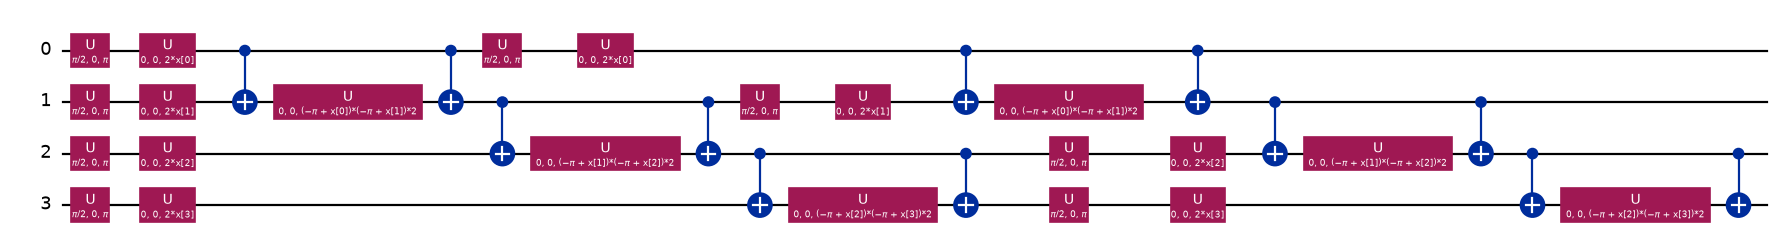

In [16]:
FM = zz_feature_map(N_QUBITS, reps=ZZ_REPS, entanglement="linear")
print("ZZ feature map: qubits", FM.num_qubits, "| depth (library blocks)", FM.depth(), "| depth decomposed to gates", FM.decompose().decompose().depth(),
      "| data parameters", FM.num_parameters, "| trainable parameters 0 (kernel method; the SVM is trained classically)")
print("gate counts after decomposition:", dict(FM.decompose().decompose().count_ops()))
fig = FM.decompose().draw("mpl", fold=40, scale=0.8); display(fig)

kernel circuit U(b)^dagger U(a): qubits 4 | depth 37 | gates {'u': 44, 'cx': 22, 'measure': 4, 'barrier': 1} | data parameters 8 | trainable parameters 0


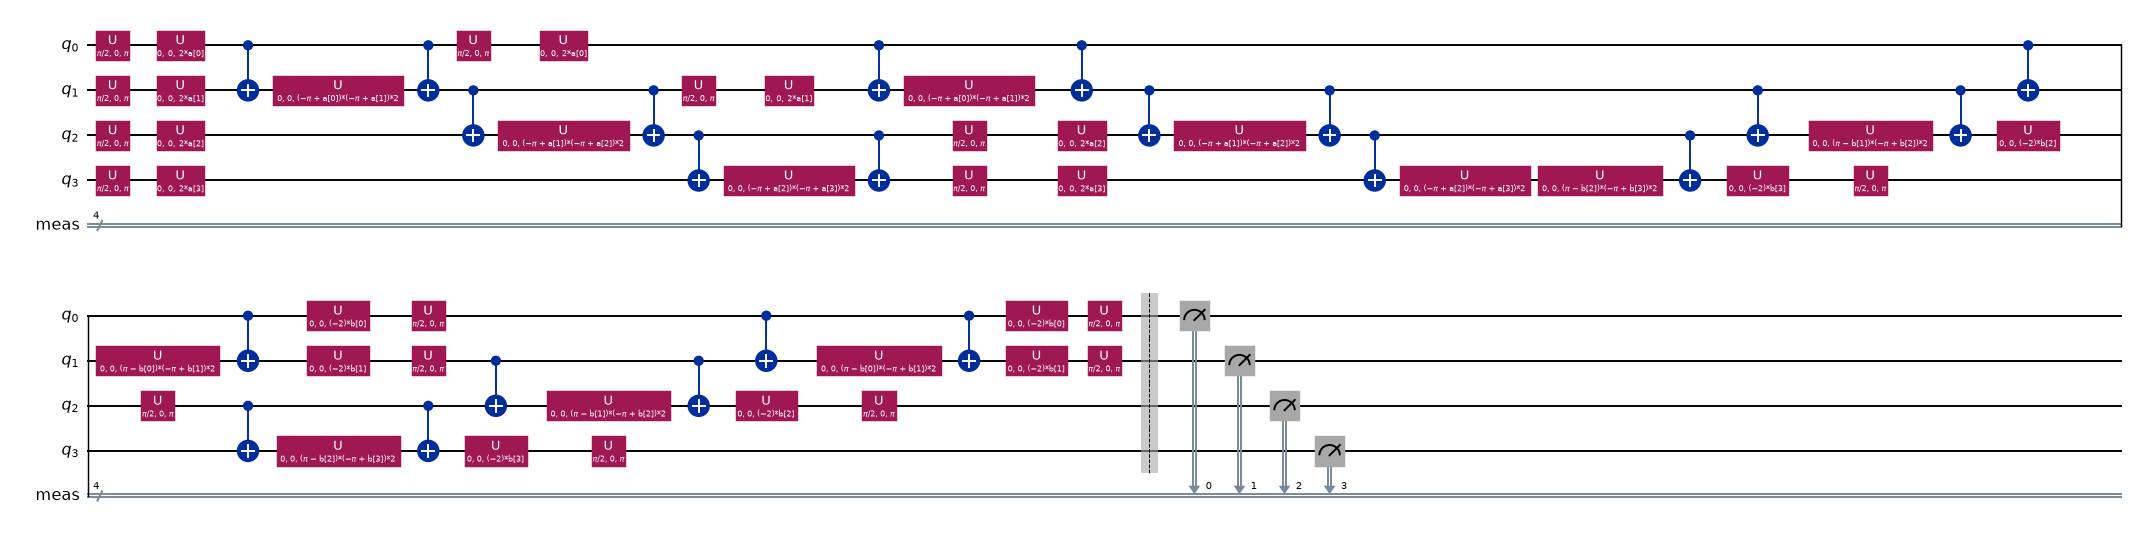

In [17]:
# the kernel circuit U(x') U(x)^dagger ... measured: exactly what the Aer sampler runs in Section 7
xa, xb = ParameterVector("a", N_QUBITS), ParameterVector("b", N_QUBITS)
KC = QuantumCircuit(N_QUBITS, name="kernel")
KC.compose(FM.assign_parameters(list(xa)), inplace=True)
KC.compose(FM.assign_parameters(list(xb)).inverse(), inplace=True)
KC.measure_all()
KC_T = transpile(KC, basis_gates=["u", "cx"], optimization_level=1, seed_transpiler=SEED)     # CHOICE: u/cx basis gets the depolarising noise
print("kernel circuit U(b)^dagger U(a): qubits", KC_T.num_qubits, "| depth", KC_T.depth(), "| gates", dict(KC_T.count_ops()), "| data parameters", KC_T.num_parameters, "| trainable parameters 0")
fig = KC_T.draw("mpl", fold=45, scale=0.7); display(fig)

BB84 circuit bit=1, Alice basis=X, Bob basis=X: qubits 1, depth 5, gates {'h': 2, 'x': 1, 'id': 1, 'measure': 1}, trainable parameters 0


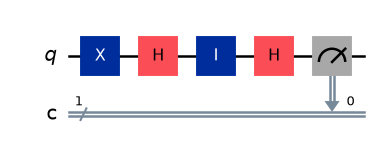

BB84 circuit bit=0, Alice basis=Z, Bob basis=X: qubits 1, depth 3, gates {'id': 1, 'h': 1, 'measure': 1}, trainable parameters 0


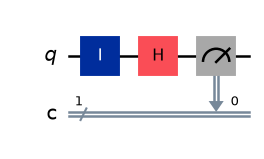

In [18]:
# BB84: two of the eight circuits (bit, Alice basis, Bob basis); noise is attached to the id gate
for key_ in [(1, 1, 1), (0, 0, 1)]:
    qc = BB84_CIRCS[key_]
    print("BB84 circuit bit=%d, Alice basis=%s, Bob basis=%s: qubits %d, depth %d, gates %s, trainable parameters 0" % (
        key_[0], "X" if key_[1] else "Z", "X" if key_[2] else "Z", qc.num_qubits, qc.depth(), dict(qc.count_ops())))
    fig = qc.draw("mpl", scale=0.9); display(fig)

## 5. Phase 3: the quantum SVM and the classical baselines, on identical inputs

**qSVM.** For every flow the 4 angles are scaled by a bandwidth, the `ZZFeatureMap` state `|phi(x)>` is computed, and the kernel is `K(x, x') = |<phi(x)|phi(x')>|^2` (Eq. 4). The Gram matrix is fed to `SVC(kernel="precomputed")` (Eq. 5, soft margin). Because the circuits have only 4 qubits, exact statevectors are used for the main experiments; the first cell below proves that this hand-made kernel is identical to Qiskit's `FidelityStatevectorKernel` and that `QSVC` gives the same predictions. Bandwidth and `C` are chosen on a validation split (25 % of the training split) and the model is then refitted on the whole training split.

**Baselines.** Decision Tree, SVM-RBF, XGBoost (the paper's three) and Random Forest, trained on exactly the **same 4 angles** that the qSVM receives, and again on **all filtered features** (standardised). The RBF-SVM gets the same validation-split tuning budget (`C` x `gamma`) as the qSVM (`C` x bandwidth); a default `SVC()` is also reported, since that is the most likely reading of the paper's "SVM (RBF kernel)".

In [19]:
def gram(Sa, Sb): return np.abs(Sa.conj() @ Sb.T) ** 2        # |<a|b>|^2 for statevectors stored as rows

def states_for(fm, A, bw):
    return np.array([Statevector(fm.assign_parameters(a * bw)).data for a in A])

# ---- equivalence check: hand-made kernel == FidelityStatevectorKernel, and QSVC == SVC(precomputed)
Pq = d0["P"]["PQC-IoT"]; Aeq = Pq.angles(d0["Xtr"]["PQC-IoT"][:40]); yeq = d0["ytr"][:40]; bw_eq = 0.5
K_hand = gram(states_for(FM, Aeq, bw_eq), states_for(FM, Aeq, bw_eq))
K_qml = FidelityStatevectorKernel(feature_map=FM).evaluate(x_vec=Aeq * bw_eq)
print("hand-made Gram == FidelityStatevectorKernel:", np.allclose(K_hand, K_qml, atol=1e-8), "| max |diff| = %.2e" % np.abs(K_hand - K_qml).max())
qsvc = QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=FM), C=10.0).fit(Aeq[:30] * bw_eq, yeq[:30])
svc_ = SVC(kernel="precomputed", C=10.0).fit(K_hand[:30, :30], yeq[:30])
print("QSVC predictions == SVC(precomputed) predictions:", np.array_equal(qsvc.predict(Aeq[30:] * bw_eq), svc_.predict(K_hand[30:, :30])))
assert np.allclose(K_hand, K_qml, atol=1e-8)

hand-made Gram == FidelityStatevectorKernel: True | max |diff| = 3.77e-15


QSVC predictions == SVC(precomputed) predictions: True


In [20]:
def inner_split(ytr, seed):
    return train_test_split(np.arange(len(ytr)), test_size=0.25, stratify=ytr, random_state=seed)

def qsvm_fit_predict(fm, Atr, ytr, Ate, seed):
    ifit, ival = inner_split(ytr, seed)
    S, tst, tse = {}, {}, {}
    for bw in BANDWIDTHS:
        t0 = time.perf_counter(); s_tr = states_for(fm, Atr, bw); tst[bw] = time.perf_counter() - t0
        t0 = time.perf_counter(); s_te = states_for(fm, Ate, bw); tse[bw] = time.perf_counter() - t0
        S[bw] = (s_tr, s_te)
    best = None
    for bw in BANDWIDTHS:
        Ktr = gram(S[bw][0], S[bw][0])
        for C in C_GRID:
            acc = SVC(kernel="precomputed", C=C).fit(Ktr[np.ix_(ifit, ifit)], ytr[ifit]).score(Ktr[np.ix_(ival, ifit)], ytr[ival])
            if best is None or acc > best[0]: best = (acc, bw, C)
    _, bw, C = best
    t0 = time.perf_counter(); Ktr = gram(S[bw][0], S[bw][0]); svc = SVC(kernel="precomputed", C=C).fit(Ktr, ytr); t_fit = tst[bw] + time.perf_counter() - t0
    t0 = time.perf_counter(); Kte = gram(S[bw][1], S[bw][0]); pred = svc.predict(Kte); score = svc.decision_function(Kte); t_pred = tse[bw] + time.perf_counter() - t0
    return dict(pred=pred, score=score, t_fit=t_fit, t_pred=t_pred, bw=bw, C=C, val_acc=best[0], Ktr=Ktr, Kte=Kte)

def rbf_fit_predict(Xtr, ytr, Xte, seed, scale_by_d):
    ifit, ival = inner_split(ytr, seed); d = Xtr.shape[1]; best = None
    for C in C_GRID:
        for g in GAMMA_GRID:
            gam = g / d if scale_by_d else g
            acc = SVC(C=C, gamma=gam).fit(Xtr[ifit], ytr[ifit]).score(Xtr[ival], ytr[ival])
            if best is None or acc > best[0]: best = (acc, C, gam)
    t0 = time.perf_counter(); m = SVC(C=best[1], gamma=best[2]).fit(Xtr, ytr); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = m.predict(Xte); score = m.decision_function(Xte); t_pred = time.perf_counter() - t0
    return dict(pred=pred, score=score, t_fit=t_fit, t_pred=t_pred, C=best[1], gamma=best[2])

def sk_fit_predict(model, Xtr, ytr, Xte):
    t0 = time.perf_counter(); model.fit(Xtr, ytr); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = model.predict(Xte); score = model.predict_proba(Xte)[:, 1]; t_pred = time.perf_counter() - t0
    return dict(pred=pred, score=score, t_fit=t_fit, t_pred=t_pred, model=model)

ROWS, OUT = [], {}
def record(seed, variant, model, inputs, yte, r):
    pred, score = np.asarray(r["pred"]), np.asarray(r["score"])
    ROWS.append(dict(seed=seed, variant=variant, model=model, inputs=inputs, acc=accuracy_score(yte, pred), prec=precision_score(yte, pred, zero_division=0),
                     rec=recall_score(yte, pred, zero_division=0), f1=f1_score(yte, pred, zero_division=0), auc=roc_auc_score(yte, score),
                     t_fit=r["t_fit"], t_pred=r["t_pred"], bw=r.get("bw", np.nan), C=r.get("C", np.nan)))
    OUT[(seed, variant, model, inputs)] = dict(yte=yte, pred=pred, score=score, extra={k: v for k, v in r.items() if k in ("Ktr", "Kte", "model", "bw", "C", "gamma")})

def run_seed(seed):
    d = get_data(seed)
    for v in VARIANTS:
        P = d["P"][v]; ytr, yte = d["ytr"], d["yte"]
        Atr, Ate = P.angles(d["Xtr"][v]), P.angles(d["Xte"][v])
        Str, Ste = P.std(d["Xtr"][v]), P.std(d["Xte"][v])
        record(seed, v, "qSVM", "4 angles", yte, qsvm_fit_predict(FM, Atr, ytr, Ate, seed))
        for inputs, (Xa, Xb, byd) in {"4 angles": (Atr, Ate, False), "all features": (Str, Ste, True)}.items():
            record(seed, v, "SVM (RBF, tuned)", inputs, yte, rbf_fit_predict(Xa, ytr, Xb, seed, byd))
            record(seed, v, "Decision Tree", inputs, yte, sk_fit_predict(DecisionTreeClassifier(random_state=seed), Xa, ytr, Xb))
            record(seed, v, "Random Forest", inputs, yte, sk_fit_predict(RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=2), Xa, ytr, Xb))
            record(seed, v, "XGBoost", inputs, yte, sk_fit_predict(XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.1, random_state=seed, n_jobs=2, eval_metric="logloss"), Xa, ytr, Xb))
        t0 = time.perf_counter(); m = SVC().fit(Atr, ytr); tf = time.perf_counter() - t0
        record(seed, v, "SVM (RBF, default)", "4 angles", yte, dict(pred=m.predict(Ate), score=m.decision_function(Ate), t_fit=tf, t_pred=0.0))

t_all = time.time()
for s in SEEDS:
    t0 = time.time(); run_seed(s)
    q = [r for r in ROWS if r["seed"] == s and r["model"] == "qSVM" and r["variant"] == "PQC-IoT"][0]
    print("seed %d done in %.0f s | qSVM (PQC-IoT): acc %.3f, bandwidth %.2f, C %g" % (s, time.time() - t0, q["acc"], q["bw"], q["C"]))
RES = pd.DataFrame(ROWS)
print("all seeds: %.1f min" % ((time.time() - t_all) / 60))

seed 42 done in 118 s | qSVM (PQC-IoT): acc 0.998, bandwidth 0.25, C 100


seed 43 done in 108 s | qSVM (PQC-IoT): acc 0.990, bandwidth 1.00, C 10


seed 44 done in 111 s | qSVM (PQC-IoT): acc 0.988, bandwidth 0.25, C 1


seed 45 done in 119 s | qSVM (PQC-IoT): acc 0.985, bandwidth 0.25, C 100


seed 46 done in 194 s | qSVM (PQC-IoT): acc 0.993, bandwidth 0.25, C 100
all seeds: 10.8 min


## 6. The paper's Table 3, recomputed

Table 3 of the paper lists accuracy, precision, recall, F1 and AUC-ROC (in %) of Decision Tree, SVM (RBF), XGBoost and qSVM on the **PQC-IoT** features. Below, the notebook's mean +- standard deviation over the seeds (attack = positive class, 20 % stratified test split) on BoT-IoT with the PQC features appended, next to the paper's values. First the *identical-input* comparison (the 4 angles the qSVM receives), then the same classical models given all filtered features.

In [21]:
PAPER3 = {"Decision Tree": (92.3, 90.1, 91.5, 90.8, 93.0), "SVM (RBF, tuned)": (96.1, 95.5, 95.9, 95.6, 96.4),
          "XGBoost": (96.8, 96.2, 96.5, 96.3, 97.5), "qSVM": (97.6, 96.9, 97.8, 97.3, 98.0)}
MET = ["acc", "prec", "rec", "f1", "auc"]
def ms(df, k): return "%.1f +- %.1f" % (100 * df[k].mean(), 100 * df[k].std(ddof=0))
def table3(variant, inputs, models):
    rows = []
    for m in models:
        d = RES[(RES.variant == variant) & (RES.model == m) & (RES.inputs == inputs)]
        row = {"model": m, "inputs": inputs}
        row.update({k: ms(d, k) for k in MET})
        if m in PAPER3 and inputs == "4 angles":
            row.update({"paper " + k: v for k, v in zip(MET, PAPER3[m])})
        row["fit s"] = round(d.t_fit.mean(), 3); rows.append(row)
    return pd.DataFrame(rows).set_index("model")
print("PQC-IoT feature set, identical 4-angle inputs (n seeds = %d)" % len(SEEDS))
display(table3("PQC-IoT", "4 angles", ["Decision Tree", "Random Forest", "SVM (RBF, default)", "SVM (RBF, tuned)", "XGBoost", "qSVM"]))
print("same classical models on all filtered features (no PCA bottleneck); qSVM cannot use them")
display(table3("PQC-IoT", "all features", ["Decision Tree", "Random Forest", "SVM (RBF, tuned)", "XGBoost"]))
print("IoT feature set (no PQC columns), identical 4-angle inputs")
display(table3("IoT", "4 angles", ["Decision Tree", "Random Forest", "SVM (RBF, default)", "SVM (RBF, tuned)", "XGBoost", "qSVM"]))

PQC-IoT feature set, identical 4-angle inputs (n seeds = 5)


,inputs,acc,prec,rec,f1,auc,paper acc,paper prec,paper rec,paper f1,paper auc,fit s
model,,,,,,,,,,,,
Decision Tree,4 angles,99.1 +- 0.4,99.0 +- 0.7,99.3 +- 0.5,99.2 +- 0.4,99.1 +- 0.4,92.3,90.1,91.5,90.8,93.0,0.016
Random Forest,4 angles,99.5 +- 0.3,99.5 +- 0.3,99.4 +- 0.5,99.4 +- 0.3,100.0 +- 0.0,NaN,NaN,NaN,NaN,NaN,2.446
"SVM (RBF, default)",4 angles,98.8 +- 0.3,98.8 +- 0.7,98.9 +- 0.4,98.9 +- 0.3,99.9 +- 0.1,NaN,NaN,NaN,NaN,NaN,0.042
"SVM (RBF, tuned)",4 angles,99.6 +- 0.3,99.5 +- 0.5,99.7 +- 0.2,99.6 +- 0.3,99.9 +- 0.2,96.1,95.5,95.9,95.6,96.4,0.038
XGBoost,4 angles,99.6 +- 0.2,99.8 +- 0.2,99.4 +- 0.5,99.6 +- 0.2,100.0 +- 0.0,96.8,96.2,96.5,96.3,97.5,6.263
qSVM,4 angles,99.0 +- 0.4,98.8 +- 0.9,99.3 +- 0.5,99.1 +- 0.4,99.9 +- 0.2,97.6,96.9,97.8,97.3,98.0,14.130


same classical models on all filtered features (no PCA bottleneck); qSVM cannot use them


,inputs,acc,prec,rec,f1,auc,fit s
model,,,,,,,
Decision Tree,all features,99.4 +- 0.6,99.2 +- 0.8,99.5 +- 0.6,99.4 +- 0.6,99.3 +- 0.6,0.032
Random Forest,all features,99.9 +- 0.1,100.0 +- 0.0,99.8 +- 0.2,99.9 +- 0.1,100.0 +- 0.0,1.468
"SVM (RBF, tuned)",all features,99.8 +- 0.2,100.0 +- 0.0,99.6 +- 0.4,99.8 +- 0.2,100.0 +- 0.0,0.047
XGBoost,all features,99.5 +- 0.4,99.8 +- 0.4,99.2 +- 0.7,99.5 +- 0.4,100.0 +- 0.0,4.949


IoT feature set (no PQC columns), identical 4-angle inputs


,inputs,acc,prec,rec,f1,auc,paper acc,paper prec,paper rec,paper f1,paper auc,fit s
model,,,,,,,,,,,,
Decision Tree,4 angles,99.4 +- 0.2,99.5 +- 0.3,99.2 +- 0.5,99.3 +- 0.2,99.4 +- 0.2,92.3,90.1,91.5,90.8,93.0,0.009
Random Forest,4 angles,99.6 +- 0.2,99.5 +- 0.4,99.6 +- 0.4,99.6 +- 0.2,100.0 +- 0.0,NaN,NaN,NaN,NaN,NaN,1.749
"SVM (RBF, default)",4 angles,98.8 +- 0.3,98.9 +- 0.6,98.6 +- 0.6,98.7 +- 0.3,99.9 +- 0.1,NaN,NaN,NaN,NaN,NaN,0.025
"SVM (RBF, tuned)",4 angles,99.5 +- 0.3,99.4 +- 0.5,99.5 +- 0.5,99.5 +- 0.3,100.0 +- 0.1,96.1,95.5,95.9,95.6,96.4,0.024
XGBoost,4 angles,99.4 +- 0.2,99.5 +- 0.5,99.3 +- 0.2,99.4 +- 0.2,100.0 +- 0.1,96.8,96.2,96.5,96.3,97.5,5.579
qSVM,4 angles,98.8 +- 0.3,99.1 +- 0.7,98.6 +- 0.9,98.8 +- 0.3,99.8 +- 0.2,97.6,96.9,97.8,97.3,98.0,9.179


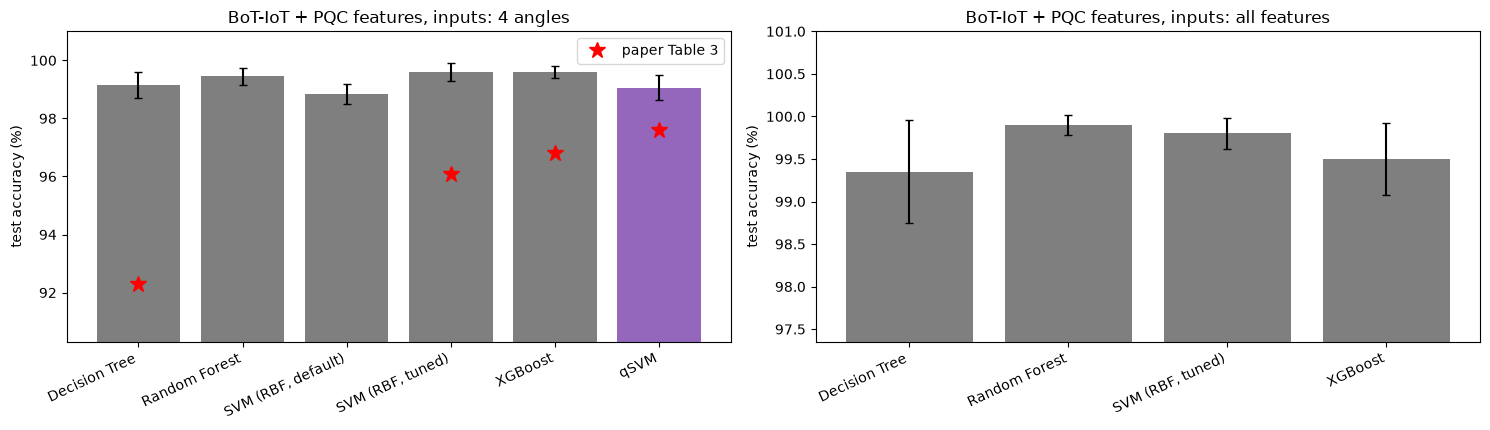

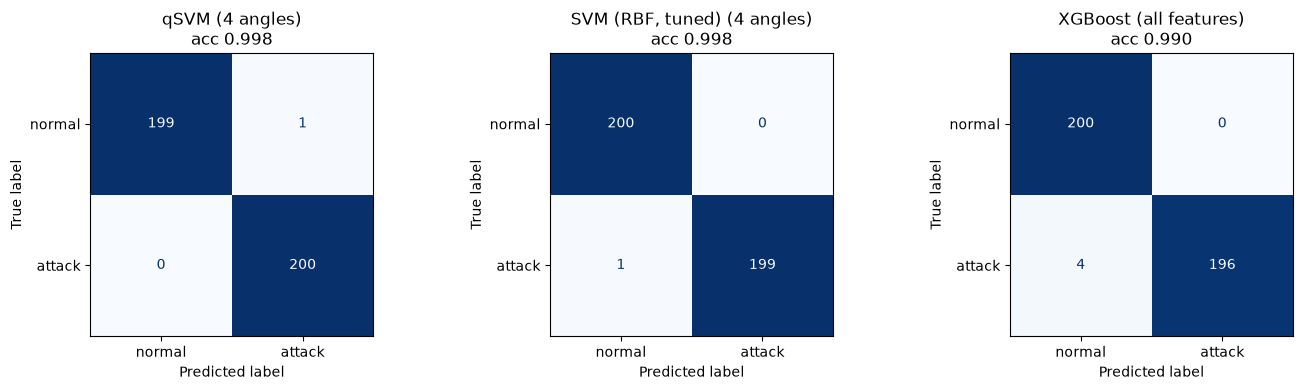

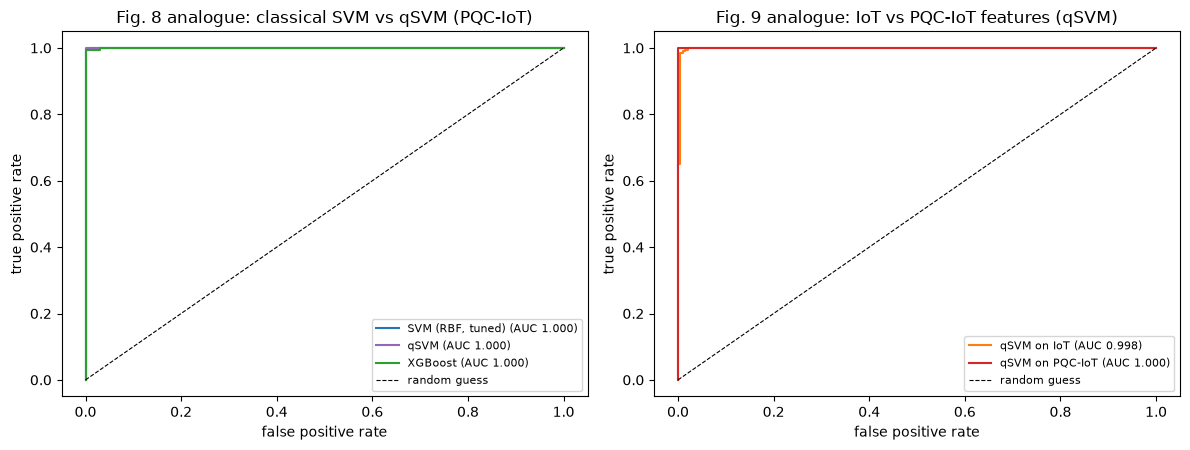

In [22]:
order = ["Decision Tree", "Random Forest", "SVM (RBF, default)", "SVM (RBF, tuned)", "XGBoost", "qSVM"]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
for j, inputs in enumerate(["4 angles", "all features"]):
    mods = [m for m in order if not RES[(RES.variant == "PQC-IoT") & (RES.model == m) & (RES.inputs == inputs)].empty]
    mu = [100 * RES[(RES.variant == "PQC-IoT") & (RES.model == m) & (RES.inputs == inputs)].acc.mean() for m in mods]
    sd = [100 * RES[(RES.variant == "PQC-IoT") & (RES.model == m) & (RES.inputs == inputs)].acc.std(ddof=0) for m in mods]
    ax[j].bar(range(len(mods)), mu, yerr=sd, capsize=3, color=["tab:purple" if m == "qSVM" else "tab:gray" for m in mods])
    for i, m in enumerate(mods):
        if m in PAPER3 and inputs == "4 angles": ax[j].plot(i, PAPER3[m][0], "r*", ms=12, label="paper Table 3" if i == 0 else None)
    ax[j].set_xticks(range(len(mods))); ax[j].set_xticklabels(mods, rotation=25, ha="right"); ax[j].set_ylim(min(mu + ([PAPER3[m][0] for m in mods if m in PAPER3] if inputs == '4 angles' else [])) - 2, 101); ax[j].set_ylabel("test accuracy (%)")
    ax[j].set_title("BoT-IoT + PQC features, inputs: %s" % inputs)
    if j == 0: ax[j].legend()
plt.tight_layout(); plt.show()

# confusion matrices (attack = positive), seed S0
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (m, inp) in zip(ax, [("qSVM", "4 angles"), ("SVM (RBF, tuned)", "4 angles"), ("XGBoost", "all features")]):
    o = OUT[(S0, "PQC-IoT", m, inp)]
    ConfusionMatrixDisplay(confusion_matrix(o["yte"], o["pred"]), display_labels=["normal", "attack"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title("%s (%s)\nacc %.3f" % (m, inp, accuracy_score(o["yte"], o["pred"])))
plt.tight_layout(); plt.show()

# ROC curves: Fig. 8 analogue (qSVM versus SVM) and Fig. 9 analogue (IoT versus PQC-IoT)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for m, c in [("SVM (RBF, tuned)", "tab:blue"), ("qSVM", "tab:purple"), ("XGBoost", "tab:green")]:
    o = OUT[(S0, "PQC-IoT", m, "4 angles")]; fpr, tpr, _ = roc_curve(o["yte"], o["score"]); ax[0].plot(fpr, tpr, color=c, label="%s (AUC %.3f)" % (m, roc_auc_score(o["yte"], o["score"])))
for v, c in [("IoT", "tab:orange"), ("PQC-IoT", "tab:red")]:
    o = OUT[(S0, v, "qSVM", "4 angles")]; fpr, tpr, _ = roc_curve(o["yte"], o["score"]); ax[1].plot(fpr, tpr, color=c, label="qSVM on %s (AUC %.3f)" % (v, roc_auc_score(o["yte"], o["score"])))
for a, t in zip(ax, ["Fig. 8 analogue: classical SVM vs qSVM (PQC-IoT)", "Fig. 9 analogue: IoT vs PQC-IoT features (qSVM)"]):
    a.plot([0, 1], [0, 1], "k--", lw=0.8, label="random guess"); a.set_xlabel("false positive rate"); a.set_ylabel("true positive rate"); a.set_title(t); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. The quantum kernel under gate noise (the paper's "91.3 % under noise")

Section 5.4 reports 94.8 % for the noiseless qSVM and 91.3 % under noise, without saying which noise model or backend. Here each kernel entry is **one circuit run on Aer** (the transpiled `U(a)` then `U(b)^dagger` circuit drawn above, 4 qubits, measured, `SHOTS` shots, probability of `0000` = kernel value):

* **exact**: statevector overlap (what Section 5 used);
* **sampled, noiseless**: Aer statevector sampler, shot noise only;
* **sampled, noisy**: Aer density-matrix simulation with a depolarising error of `P1_ERR` on every `u` gate and `P2_ERR` on every `cx` (`# CHOICE:` a generic NISQ-like model; the paper gives none).

Each kernel entry needs a separate circuit, so the study uses a **reduced stratified subsample** of the seed-`S0` split (`NOISE_TRAIN` training and `NOISE_TEST` test flows; every training pair and every test-train pair is one circuit). The classical RBF-SVM on the same subsample is the reference.

noise study: 150 training / 100 test flows, bandwidth 0.25, C 100, 1024 shots, circuits: 11175 (train pairs) + 15000 (test x train) per kernel


sampled, noiseless             555 s


sampled, noisy (depolarising)  763 s


sampled, 5x stronger noise     801 s
max |sampled noiseless - exact| over the training kernel: 0.052 (binomial std of one entry <= 0.016 for 1024 shots) -> circuit == statevector kernel


,acc,f1,mean_offdiag,mean_abs_dev_from_exact,train_acc
kernel,,,,,
exact (statevector),0.99,0.990,0.193,0.000,1.0
"sampled, noiseless",0.95,0.948,0.193,0.006,1.0
"sampled, noisy (depolarising)",0.99,0.990,0.168,0.032,1.0
"sampled, 5x stronger noise",0.98,0.980,0.108,0.106,1.0
classical RBF-SVM on the same 4 angles,1.00,1.000,NaN,NaN,NaN


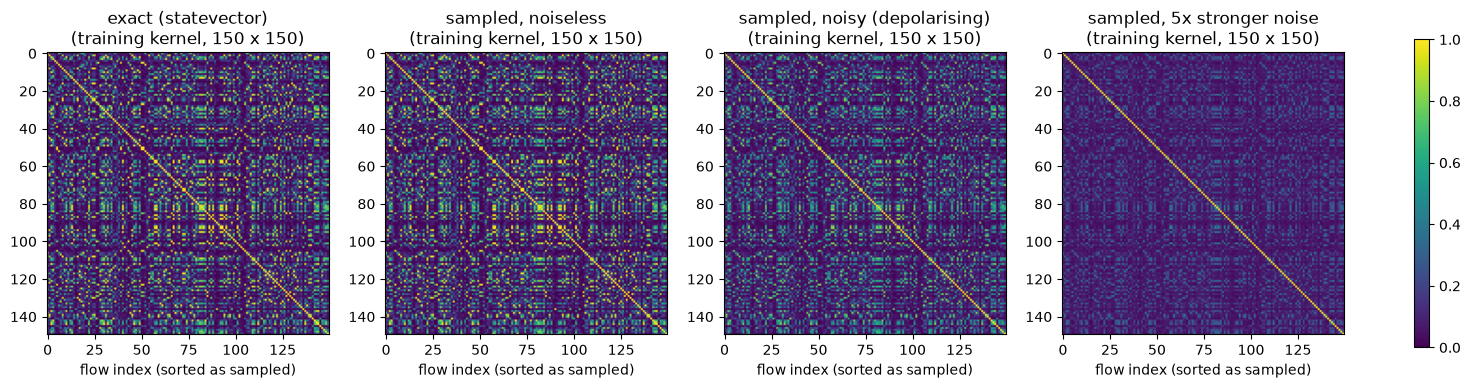

In [23]:
names = [p.name for p in KC_T.parameters]
assert names == ["a[%d]" % i for i in range(N_QUBITS)] + ["b[%d]" % i for i in range(N_QUBITS)], names

def sampled_kernel(A, B, bw, noise, scale=1.0):
    # kernel entries |<phi(a)|phi(b)>|^2 estimated from SHOTS shots of the transpiled kernel circuit (all-zero outcome)
    sym = B is None
    if sym:
        iu = np.triu_indices(len(A), 1); vals = np.hstack([A[iu[0]], A[iu[1]]]) * bw
    else:
        ia, ib = np.meshgrid(np.arange(len(A)), np.arange(len(B)), indexing="ij"); vals = np.hstack([A[ia.ravel()], B[ib.ravel()]]) * bw
    opts = dict(seed_simulator=SEED)
    if noise:
        nm = NoiseModel(); nm.add_all_qubit_quantum_error(depolarizing_error(P1_ERR * scale, 1), ["u"]); nm.add_all_qubit_quantum_error(depolarizing_error(P2_ERR * scale, 2), ["cx"])
        opts.update(noise_model=nm, method="density_matrix")
    sampler = AerSamplerV2(options=dict(backend_options=opts))
    arr = sampler.run([(KC_T, vals)], shots=SHOTS).result()[0].data.meas.array
    p0 = np.all(arr == 0, axis=2).mean(axis=1)
    if sym:
        K = np.eye(len(A)); K[iu] = p0; K = K + K.T - np.eye(len(A)); return K
    return p0.reshape(len(A), len(B))

dn = get_data(S0); Pn = dn["P"]["PQC-IoT"]
qrow = OUT[(S0, "PQC-IoT", "qSVM", "4 angles")]["extra"]; BW_N, C_N = qrow["bw"], qrow["C"]
itr_s, _ = train_test_split(np.arange(len(dn["itr"])), train_size=NOISE_TRAIN, stratify=dn["ytr"], random_state=SEED)
ite_s, _ = train_test_split(np.arange(len(dn["ite"])), train_size=NOISE_TEST, stratify=dn["yte"], random_state=SEED)
An_tr, An_te = Pn.angles(dn["Xtr"]["PQC-IoT"][itr_s]), Pn.angles(dn["Xte"]["PQC-IoT"][ite_s]); yn_tr, yn_te = dn["ytr"][itr_s], dn["yte"][ite_s]
print("noise study: %d training / %d test flows, bandwidth %.2f, C %g, %d shots, circuits: %d (train pairs) + %d (test x train) per kernel" % (
    NOISE_TRAIN, NOISE_TEST, BW_N, C_N, SHOTS, NOISE_TRAIN * (NOISE_TRAIN - 1) // 2, NOISE_TRAIN * NOISE_TEST))

t0 = time.time(); S_tr, S_te = states_for(FM, An_tr, BW_N), states_for(FM, An_te, BW_N)
KN = {"exact (statevector)": (gram(S_tr, S_tr), gram(S_te, S_tr))}
for label, noise, scale in [("sampled, noiseless", False, 1), ("sampled, noisy (depolarising)", True, 1), ("sampled, 5x stronger noise", True, 5)]:
    t0 = time.time(); KN[label] = (sampled_kernel(An_tr, None, BW_N, noise, scale), sampled_kernel(An_te, An_tr, BW_N, noise, scale)); print("%-30s %.0f s" % (label, time.time() - t0))
ok = np.abs(KN["sampled, noiseless"][0] - KN["exact (statevector)"][0]).max()
print("max |sampled noiseless - exact| over the training kernel: %.3f (binomial std of one entry <= %.3f for %d shots) -> circuit == statevector kernel" % (ok, 0.5 / np.sqrt(SHOTS), SHOTS))
assert ok < 6 * 0.5 / np.sqrt(SHOTS)
NZ = []
for label, (Ktr_, Kte_) in KN.items():
    svc = SVC(kernel="precomputed", C=C_N).fit(Ktr_, yn_tr); pr = svc.predict(Kte_)
    NZ.append(dict(kernel=label, acc=accuracy_score(yn_te, pr), f1=f1_score(yn_te, pr), mean_offdiag=float((Ktr_.sum() - len(Ktr_)) / (Ktr_.size - len(Ktr_))),
                   mean_abs_dev_from_exact=float(np.abs(Ktr_ - KN['exact (statevector)'][0]).mean()), train_acc=float(svc.score(Ktr_, yn_tr))))
m_ = SVC(C=1.0, gamma=1.0).fit(An_tr, yn_tr); pr = m_.predict(An_te)
NZ.append(dict(kernel="classical RBF-SVM on the same 4 angles", acc=accuracy_score(yn_te, pr), f1=f1_score(yn_te, pr), mean_offdiag=np.nan))
NZ = pd.DataFrame(NZ).set_index("kernel"); display(NZ.round(3))
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, (label, (Ktr_, _)) in zip(ax, KN.items()):
    im = a.imshow(Ktr_, vmin=0, vmax=1, cmap="viridis"); a.set_title(label + "\n(training kernel, %d x %d)" % Ktr_.shape); a.set_xlabel("flow index (sorted as sampled)")
plt.colorbar(im, ax=ax, fraction=0.02); plt.show()

## 8. Do the PQC features help? (the paper's Fig. 9 and feature-importance claim)

The paper states that PQC attributes such as encryption latency "significantly enhanced anomaly detection". Three checks: (a) the accuracy of every model with and without the three columns (mean over seeds, difference in points), (b) how much each PQC column says about the label **on its own** (single-feature AUC; 0.5 means no information), and (c) what a tree ensemble thinks of them (XGBoost gain on all filtered features).

IoT  PQC_IoT  delta_points  delta_std
model              inputs                                               
Decision Tree      4 angles      99.35    99.15         -0.20       0.48
                   all features  99.50    99.35         -0.15       0.34
Random Forest      4 angles      99.55    99.45         -0.10       0.20
                   all features  99.90    99.90          0.00       0.00
SVM (RBF, default) 4 angles      98.75    98.85          0.10       0.20
SVM (RBF, tuned)   4 angles      99.45    99.60          0.15       0.20
                   all features  99.75    99.80          0.05       0.10
XGBoost            4 angles      99.40    99.60          0.20       0.33
                   all features  99.50    99.50          0.00       0.00
qSVM               4 angles      98.85    99.05          0.20       0.37

,AUC of the feature alone,|AUC - 0.5|
pqc_enc_ms,0.511,0.011
pqc_ct_bytes,0.601,0.101
pqc_keygen_ms,0.512,0.012
bytes (BoT-IoT),0.588,0.088
dur (BoT-IoT),0.605,0.105
pkts (BoT-IoT),0.734,0.234


XGBoost gain share of the PQC columns: 0.1 % (of 35 features kept by the filter; ['pqc_enc_ms', 'pqc_ct_bytes', 'pqc_keygen_ms'])


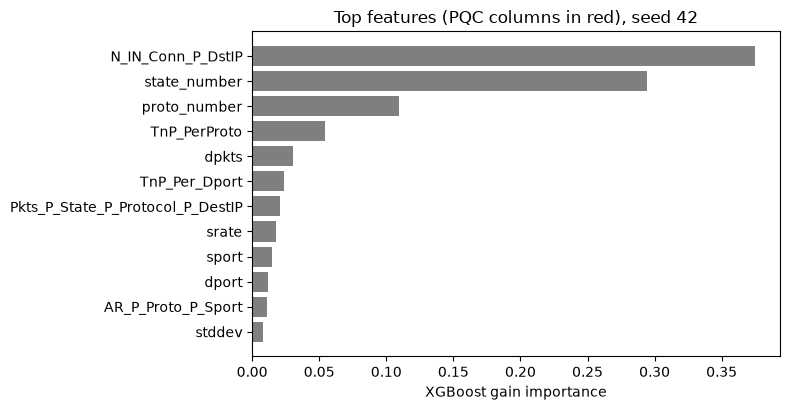

In [24]:
ab = []
for (m, inp), g in RES[RES.variant.isin(["IoT", "PQC-IoT"])].groupby(["model", "inputs"]):
    a0 = g[g.variant == "IoT"].sort_values("seed").acc.values; a1 = g[g.variant == "PQC-IoT"].sort_values("seed").acc.values
    ab.append(dict(model=m, inputs=inp, IoT=100 * a0.mean(), PQC_IoT=100 * a1.mean(), delta_points=100 * (a1 - a0).mean(), delta_std=100 * (a1 - a0).std(ddof=0)))
AB = pd.DataFrame(ab).set_index(["model", "inputs"]); display(AB.round(2))

dfa = d0["df"]
single = pd.DataFrame({"AUC of the feature alone": [roc_auc_score(dfa["attack"], dfa[f]) for f in PQC_FEATS + ["bytes", "dur", "pkts"]]}, index=PQC_FEATS + ["bytes (BoT-IoT)", "dur (BoT-IoT)", "pkts (BoT-IoT)"])
single["|AUC - 0.5|"] = (single.iloc[:, 0] - 0.5).abs(); display(single.round(3))

mx = OUT[(S0, "PQC-IoT", "XGBoost", "all features")]["extra"]["model"]; Pp = d0["P"]["PQC-IoT"]
fn = np.array(VARIANTS["PQC-IoT"])[Pp.keep]; imp = pd.Series(mx.feature_importances_, index=fn).sort_values(ascending=False)
share = imp[[f for f in PQC_FEATS if f in imp.index]].sum()
print("XGBoost gain share of the PQC columns: %.1f %% (of %d features kept by the filter; %s)" % (100 * share, len(fn), [f for f in PQC_FEATS if f in imp.index]))
fig, ax = plt.subplots(figsize=(8, 4.2)); top = imp.head(12)[::-1]
ax.barh(top.index, top.values, color=["tab:red" if i in PQC_FEATS else "tab:gray" for i in top.index]); ax.set_xlabel("XGBoost gain importance"); ax.set_title("Top features (PQC columns in red), seed %d" % S0)
plt.tight_layout(); plt.show()

## 9. Training-time scaling (Fig. 10) and the qubit count

**Scaling.** Fig. 10 shows classical linear-kernel SVM time growing about linearly and qSVM time quadratically in the number of samples. On hardware the quadratic part is real: the Gram matrix needs `n(n-1)/2` circuit executions (listed below). On a statevector simulator the cost splits into `n` state preparations (linear) and an `n x n` overlap product (very cheap), so the *measured* exponent can differ; both the measured time and the circuit count are reported.

**Qubits.** The paper does not say how many qubits its qSVM uses (figures show 3). The notebook sweeps 3, 4 and 6 PCA angles for seed `S0` and the PQC-IoT features.

,qSVM_s,states_s,gram_s,svc_fit_s,linearSVM_s,rbfSVM_s,circuits_hw
n,,,,,,,
200,1.2867,1.2818,0.0011,0.0038,0.0049,0.0051,19900
400,1.9008,1.8825,0.0151,0.0033,0.0043,0.0041,79800
800,3.9144,3.8717,0.0354,0.0073,0.0076,0.0089,319600
1600,7.0433,6.8913,0.1170,0.0349,0.0342,0.0215,1279200
2400,11.6232,11.2837,0.2807,0.0588,0.0739,0.0321,2878800


fitted log-log exponents: {'qSVM total (simulator)': np.float64(0.89), 'linear SVM': np.float64(1.16), 'RBF SVM': np.float64(0.83), 'hardware circuits n(n-1)/2': np.float64(2.0)}


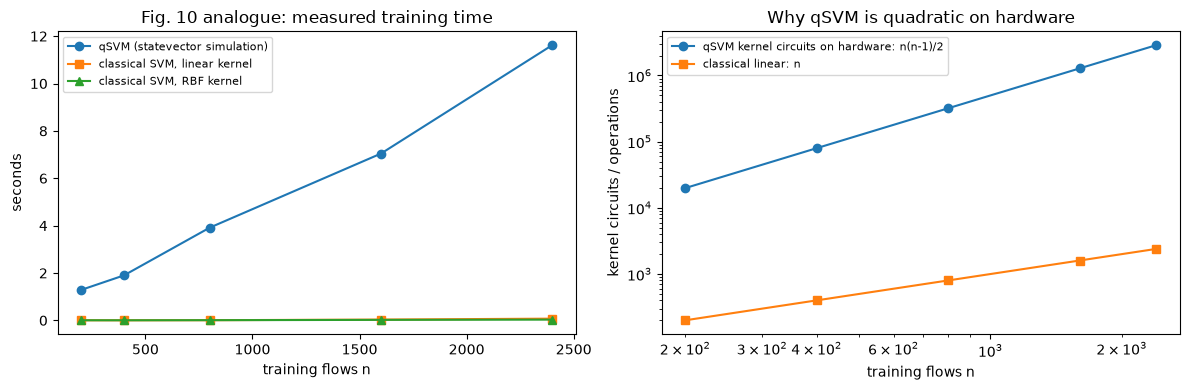

In [25]:
sc_rows = []
for n in TIMING_N:
    dfn = sample_flows(n // 2, S0); yn = dfn["attack"].values; Xn = dfn[FEATS].values.astype(float)
    Pn_ = Prep(N_QUBITS).fit(Xn); An = Pn_.angles(Xn)
    t0 = time.perf_counter(); Sn = states_for(FM, An, BW_N); t_state = time.perf_counter() - t0
    def best_of(fn, k=3):
        out = []
        for _ in range(k):
            t0 = time.perf_counter(); fn(); out.append(time.perf_counter() - t0)
        return min(out)
    Kn = gram(Sn, Sn); t_gram = best_of(lambda: gram(Sn, Sn))
    t_fitq = best_of(lambda: SVC(kernel="precomputed", C=C_N).fit(Kn, yn))
    t_lin = best_of(lambda: SVC(kernel="linear", C=1.0).fit(An, yn))
    t_rbf = best_of(lambda: SVC(kernel="rbf", C=1.0).fit(An, yn))
    sc_rows.append(dict(n=n, qSVM_s=t_state + t_gram + t_fitq, states_s=t_state, gram_s=t_gram, svc_fit_s=t_fitq, linearSVM_s=t_lin, rbfSVM_s=t_rbf, circuits_hw=n * (n - 1) // 2))
SC = pd.DataFrame(sc_rows).set_index("n"); display(SC.round(4))
slope = lambda col: np.polyfit(np.log(SC.index.values), np.log(SC[col].values), 1)[0]
EXP = {"qSVM total (simulator)": slope("qSVM_s"), "linear SVM": slope("linearSVM_s"), "RBF SVM": slope("rbfSVM_s"), "hardware circuits n(n-1)/2": slope("circuits_hw")}
print("fitted log-log exponents:", {k: round(v, 2) for k, v in EXP.items()})
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(SC.index, SC.qSVM_s, "o-", label="qSVM (statevector simulation)"); ax[0].plot(SC.index, SC.linearSVM_s, "s-", label="classical SVM, linear kernel"); ax[0].plot(SC.index, SC.rbfSVM_s, "^-", label="classical SVM, RBF kernel")
ax[0].set_xlabel("training flows n"); ax[0].set_ylabel("seconds"); ax[0].set_title("Fig. 10 analogue: measured training time"); ax[0].legend(fontsize=8)
ax[1].loglog(SC.index, SC.circuits_hw, "o-", label="qSVM kernel circuits on hardware: n(n-1)/2"); ax[1].loglog(SC.index, SC.index, "s-", label="classical linear: n")
ax[1].set_xlabel("training flows n"); ax[1].set_ylabel("kernel circuits / operations"); ax[1].set_title("Why qSVM is quadratic on hardware"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [26]:
qs = []
for nq in QUBIT_SWEEP:
    dq = get_data(S0, n_comp=nq); Pq_ = dq["P"]["PQC-IoT"]; fmq = zz_feature_map(nq, reps=ZZ_REPS, entanglement="linear")
    Atr_, Ate_ = Pq_.angles(dq["Xtr"]["PQC-IoT"]), Pq_.angles(dq["Xte"]["PQC-IoT"])
    t0 = time.time(); rq = qsvm_fit_predict(fmq, Atr_, dq["ytr"], Ate_, S0); rr = rbf_fit_predict(Atr_, dq["ytr"], Ate_, S0, False)
    qs.append(dict(qubits=nq, explained_variance=Pq_.pca.explained_variance_ratio_.sum(), qSVM_acc=accuracy_score(dq["yte"], rq["pred"]),
                   SVM_acc=accuracy_score(dq["yte"], rr["pred"]), bandwidth=rq["bw"], C=rq["C"], seconds=time.time() - t0))
QS = pd.DataFrame(qs).set_index("qubits"); display(QS.round(3))

,explained_variance,qSVM_acc,SVM_acc,bandwidth,C,seconds
qubits,,,,,,
3,0.569,0.998,0.992,0.25,10.0,24.812
4,0.634,0.998,0.998,0.25,100.0,47.370
6,0.737,1.000,0.998,0.25,10.0,108.279


## 10. PQC cost relative to classification (the "5 to 7 % overhead")

Section 5.6 says the PQC layer adds "5 to 7 % additional overhead" but does not define the baseline (energy? latency? per flow or per batch?). The only quantity measurable here is **time**: the per-flow encryption latency `T_i` measured above, against the per-flow classification time of each model (test-set prediction time divided by the number of test flows; for the qSVM this includes building the 4-qubit state of every test flow). The Raspberry Pi 3 figure (4.2 ms) cannot be checked on this machine.

In [27]:
nte = len(d0["yte"]); T_enc = d0["df"]["pqc_enc_ms"].mean(); T_key = d0["df"]["pqc_keygen_ms"].mean()
ov = []
for m, inp in [("qSVM", "4 angles"), ("SVM (RBF, tuned)", "4 angles"), ("XGBoost", "all features"), ("Decision Tree", "all features")]:
    t_clf = 1e3 * RES[(RES.variant == "PQC-IoT") & (RES.model == m) & (RES.inputs == inp)].t_pred.mean() / nte
    ov.append(dict(model=m, inputs=inp, classify_ms_per_flow=t_clf, encrypt_ms_per_flow=T_enc, keygen_ms_per_flow=T_key,
                   encrypt_share_pct=100 * T_enc / (T_enc + t_clf), encrypt_plus_keygen_share_pct=100 * (T_enc + T_key) / (T_enc + T_key + t_clf)))
OV = pd.DataFrame(ov).set_index("model"); display(OV.round(3))
print("mean Kyber-512 + AES-GCM encryption on this machine: %.2f ms per flow (paper: 4.2 ms on a Raspberry Pi 3, liboqs C code)" % T_enc)

,inputs,classify_ms_per_flow,encrypt_ms_per_flow,keygen_ms_per_flow,encrypt_share_pct,encrypt_plus_keygen_share_pct
model,,,,,,
qSVM,4 angles,6.435,2.666,1.965,29.293,41.846
"SVM (RBF, tuned)",4 angles,0.057,2.666,1.965,97.914,98.788
XGBoost,all features,0.067,2.666,1.965,97.559,98.580
Decision Tree,all features,0.004,2.666,1.965,99.853,99.916


mean Kyber-512 + AES-GCM encryption on this machine: 2.67 ms per flow (paper: 4.2 ms on a Raspberry Pi 3, liboqs C code)


## 11. Side by side with the paper

Verdict rule (repository convention): a number is **reproduced** when the notebook is within 2 accuracy points (0.02 for F1, AUC, precision and recall) of the paper's value, **exceeded** when higher by more, **not reached** when lower by more; a qualitative statement is **reproduced** when it holds in the notebook's data. **Cannot be checked** when data, hardware or the definition is missing. Remember that the data set is a stand-in: even a match is a statement about BoT-IoT flows, not about the authors' private PQC-IoT set.

In [28]:
def mean_of(variant, model, inputs, key):
    return float(RES[(RES.variant == variant) & (RES.model == model) & (RES.inputs == inputs)][key].mean())
def std_of(variant, model, inputs, key):
    return float(RES[(RES.variant == variant) & (RES.model == model) & (RES.inputs == inputs)][key].std(ddof=0))
def verdict_num(v, target, tol=0.02):
    return "reproduced" if abs(v - target) <= tol else ("exceeded" if v > target else "not reached")

rows = []
def add(cid, claim, paper, nb, verdict): rows.append(dict(claim_id=cid, claim=claim, paper=paper, notebook=nb, verdict=verdict))

# C1: Table 3 numbers (identical 4-angle inputs, PQC-IoT features)
for m in ["qSVM", "SVM (RBF, tuned)", "XGBoost", "Decision Tree"]:
    for k, kn in zip(MET, ["accuracy", "precision", "recall", "F1", "AUC-ROC"]):
        if m != "qSVM" and k not in ("acc",): continue
        v = mean_of("PQC-IoT", m, "4 angles", k); p = PAPER3[m][MET.index(k)]
        add("C1", "Table 3: %s %s" % (m, kn), "%.1f" % p, "%.1f +- %.1f" % (100 * v, 100 * std_of("PQC-IoT", m, "4 angles", k)), verdict_num(v, p / 100))
# C2: qSVM best of all and gap to SVM
accs = {m: mean_of("PQC-IoT", m, "4 angles", "acc") for m in ["Decision Tree", "SVM (RBF, tuned)", "XGBoost", "qSVM"]}
best = max(accs, key=accs.get)
add("C2a", "qSVM has the highest accuracy of the four Table 3 models", "qSVM 97.6 > XGBoost 96.8 > SVM 96.1 > DT 92.3", ", ".join("%s %.1f" % (k, 100 * v) for k, v in sorted(accs.items(), key=lambda kv: -kv[1])),
    "reproduced" if best == "qSVM" else "not reached (best: %s)" % best)
gap = 100 * (accs["qSVM"] - accs["SVM (RBF, tuned)"]); gap_def = 100 * (accs["qSVM"] - mean_of("PQC-IoT", "SVM (RBF, default)", "4 angles", "acc"))
add("C2b", "qSVM beats the classical SVM (Table 3 / BoT-IoT: +1.5 points; abstract: +4 to 7 %)", "+1.5 (Table 3), +4 to +7 (abstract)", "%+.2f vs tuned SVM, %+.2f vs default SVM (IoT features, no PQC: %+.2f)" % (
    gap, gap_def, 100 * (mean_of("IoT", "qSVM", "4 angles", "acc") - mean_of("IoT", "SVM (RBF, tuned)", "4 angles", "acc"))),
    "reproduced" if gap >= 1.0 else "not reached")
best_all = max(("Decision Tree", "Random Forest", "XGBoost", "SVM (RBF, tuned)"), key=lambda m: mean_of("PQC-IoT", m, "all features", "acc"))
add("C2c", "qSVM still best against classical models given all features", "n/a (paper does not test it)", "qSVM %.1f vs best classical (%s, all features) %.1f" % (
    100 * accs["qSVM"], best_all, 100 * mean_of("PQC-IoT", best_all, "all features", "acc")), "reproduced" if accs["qSVM"] >= mean_of("PQC-IoT", best_all, "all features", "acc") else "not reached")
# C3: noise
ideal, noisy = NZ.loc["exact (statevector)", "acc"], NZ.loc["sampled, noisy (depolarising)", "acc"]
add("C3", "Noise costs the qSVM about 3.5 points (94.8 noiseless -> 91.3 noisy)", "94.8 -> 91.3 (drop 3.5)", "%.1f -> %.1f (drop %.1f) on %d train / %d test flows; with 5x stronger gate noise: %.1f" % (100 * ideal, 100 * noisy, 100 * (ideal - noisy), NOISE_TRAIN, NOISE_TEST, 100 * NZ.loc["sampled, 5x stronger noise", "acc"]),
    "reproduced" if abs(100 * (ideal - noisy) - 3.5) <= 2 else ("exceeded (larger drop)" if ideal - noisy > 0.055 else "not reached (smaller drop)"))
# C4: PQC features help
dq_ = AB.loc[("qSVM", "4 angles")]; dx_ = AB.loc[("XGBoost", "all features")]
add("C4", "PQC features improve detection (Fig. 9, Sec. 5.7)", "PQC-IoT > IoT, 'significantly'", "qSVM %+.2f +- %.2f points, XGBoost(all) %+.2f; single-feature AUC of T/C/K: %s" % (
    dq_.delta_points, dq_.delta_std, dx_.delta_points, ", ".join("%.2f" % single.iloc[i, 0] for i in range(3))),
    "reproduced" if dq_.delta_points >= 1.0 else "not reached (no measurable gain here)")
# C5: variance
sd = 100 * std_of("PQC-IoT", "qSVM", "4 angles", "acc")
add("C5", "variance over independent runs below 0.5 %", "< 0.5 % over 5 runs", "qSVM accuracy std %.2f points over %d seeds (%d test flows each)" % (sd, len(SEEDS), len(d0["yte"])), "reproduced" if sd < 0.5 else "not reached")
# C6: BB84
agree = bool((np.abs(BB.QBER - BB.theory) <= 4 * BB.se + 0.005).all())
thr = {k: (BB[(BB.noise == k) & (BB["QBER<11%"])].strength.max()) for k in BB.noise.unique()}
add("C6", "BB84 QBER stays below 11 % under depolarising, amplitude-damping and phase-flip noise", "< 11 % (strengths not given)",
    "Aer QBER matches theory in all %d settings: %s; QBER < 11 %% up to strength %s" % (len(BB), agree, ", ".join("%s %.2f" % (k, v) for k, v in thr.items())),
    "reproduced (conditional on noise strength; threshold crossed above these values)" if agree else "not reproduced (simulation disagrees with theory)")
add("C6b", "QBER formula E[QBER] = p/2 for the depolarising channel (Sec. 3.3)", "p/2", "Aer and NumPy give 2p/3 (e.g. p=0.2: %.3f)" % BB[(BB.noise == "depolarizing") & (np.isclose(BB.strength, 0.2))].QBER.iloc[0], "not reached (formula inconsistent with the paper's own channel)")
# C7: Kyber timing + overhead
add("C7a", "Kyber-512 encryption 4.2 ms per message (Raspberry Pi 3, liboqs)", "4.2 ms", "%.2f ms (encaps + AES-GCM, pure Python on this CPU); key generation %.2f ms" % (T_enc, T_key), "cannot be checked (hardware- and library-specific)")
add("C7b", "PQC overhead 5 to 7 %", "5 to 7 % (baseline undefined)", "encryption = %.0f %% to %.0f %% of (encryption + classification time) per flow" % (OV.encrypt_share_pct.min(), OV.encrypt_share_pct.max()), "cannot be checked (baseline not defined; no energy meter)")
# C8: scaling
add("C8", "Training time: classical linear SVM ~ O(n), qSVM ~ O(n^2)", "O(n) vs O(n^2) (Fig. 10)", "fitted exponents: " + ", ".join("%s %.2f" % (k, v) for k, v in EXP.items()),
    "reproduced (circuit count is quadratic; simulator time %s)" % ("also super-linear" if EXP["qSVM total (simulator)"] > 1.4 else "is dominated by linear state preparation"))
add("C9", "Data set: > 100,000 records, 12 classes (9 attacks, 3 benign), Raspberry Pi sensors", "private PQC-IoT", "BoT-IoT stand-in: %d flows per run, binary" % len(d0["df"]), "cannot be checked (data not released)")
COMPARISON = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 120); display(COMPARISON.set_index("claim_id"))
print(COMPARISON.verdict.str.split(" ").str[0].value_counts().to_dict())

,claim,paper,notebook,verdict
claim_id,,,,
C1,Table 3: qSVM accuracy,97.6,99.0 +- 0.4,reproduced
C1,Table 3: qSVM precision,96.9,98.8 +- 0.9,reproduced
C1,Table 3: qSVM recall,97.8,99.3 +- 0.5,reproduced
C1,Table 3: qSVM F1,97.3,99.1 +- 0.4,reproduced
C1,Table 3: qSVM AUC-ROC,98.0,99.9 +- 0.2,reproduced
C1,"Table 3: SVM (RBF, tuned) accuracy",96.1,99.6 +- 0.3,exceeded
C1,Table 3: XGBoost accuracy,96.8,99.6 +- 0.2,exceeded
C1,Table 3: Decision Tree accuracy,92.3,99.1 +- 0.4,exceeded
C2a,qSVM has the highest accuracy of the four Table 3 models,qSVM 97.6 > XGBoost 96.8 > SVM 96.1 > DT 92.3,"SVM (RBF, tuned) 99.6, XGBoost 99.6, Decision Tree 99.1, qSVM 99.0","not reached (best: SVM (RBF, tuned))"


{'reproduced': 8, 'not': 6, 'exceeded': 3, 'cannot': 3}


### Summary of the comparison (full run, 5 seeds, 1,000 flows per class, 4 qubits)

* **Table 3 and the quantum advantage are not reproduced.** On BoT-IoT every model is at the ceiling: qSVM 99.0 +- 0.4 % accuracy (F1 99.1, AUC 99.9), against SVM-RBF 99.6, XGBoost 99.6 and Decision Tree 99.1 on the same 4 angles, and 99.4 to 99.9 for the classical models on all features. The numbers sit *above* the paper's baselines (96.1 / 96.8 / 92.3) and the qSVM sits inside the 2-point band around the paper's 97.6, but the qualitative claim (qSVM best, +1.5 to +7 points over SVM) is **not** reproduced: the qSVM is 0.5 points *below* the tuned SVM, within seed noise.
* **The PQC columns give no measurable gain** (+0.2 +- 0.4 points for the qSVM, 0.0 for XGBoost, single-feature AUC of the two timing features about 0.51). Only the ciphertext size carries a little signal, because it is a function of the flow's byte count.
* **BB84 is reproduced as a protocol**: Aer QBER matches theory in all 21 settings, stays below 11 % for depolarising `p <= 0.15`, amplitude damping `gamma <= 0.20`, phase flip `p <= 0.20`, and an intercept-resend eavesdropper gives 25 %. The paper's `E[QBER] = p/2` is contradicted by its own channel (it is `2p/3`; the "not reached" verdict in row C6b means exactly that).
* **Noise study**: with the generic depolarising model the kernel changes (mean absolute deviation 0.03, 5x noise 0.11) but test accuracy on 100 flows stays at 98 to 99 %, so the paper's 3.5-point drop is not seen; with 1024 shots alone the qSVM already loses accuracy (95 %), a shot-noise effect that the paper does not discuss.
* **Scaling (C8)**: the quadratic growth is real for the number of kernel circuits on hardware (`n(n-1)/2`, fitted exponent 2.00). On the statevector simulator the wall time is dominated by `n` state preparations, so the measured exponent is below 1, and the classical SVM times are milliseconds with scatter; the row's "reproduced" refers to the circuit count only.
* **Cannot be checked**: Raspberry Pi timing (4.2 ms), the 5 to 7 % overhead, energy, the private data set.

## 12. Reading the paper critically

* **The headline data set is not available and not described well enough to rebuild.** Everything that is "the paper's result" (Table 3, 94.8 % / 91.3 %, the PQC-feature benefit) is on a Raspberry Pi data set with 12 classes whose class counts, split, feature list (only about ten of "30+" features are named) and release are missing. The preprint calls the work "the first reproducible benchmark", but no code or data link is given. Anything this notebook reports is about BoT-IoT.
* **Internal inconsistencies in the numbers.** Section 5.4 says the *noiseless* qSVM reaches 94.8 % and beats the classical SVM by 4.6 % (so SVM ~ 90.2 %); Table 3 gives qSVM 97.6 % and SVM 96.1 % for the same data; the abstract says "4 to 7 %" gains, Section 5.5 says 1.5 points. Figure 3 and Figure 5 (and the text) place `RZ`/`H` and `CZ` layers and "3 features"; the feature map actually used and the number of qubits for 30+ features are never stated.
* **How do 30+ features enter 3 qubits?** Not described. PCA is mentioned only as *future work* (Section 5.7), so the quantum model's input in Table 3 is undefined. The classical baselines' inputs and hyper-parameters are not given either, so "qSVM beats SVM and XGBoost" compares an unknown input with an unknown tuning. In this notebook all models see identical 4 angles and the same tuning budget, and the classical models are additionally shown on all features.
* **BoT-IoT is nearly separable**, so every reasonable classifier is at the ceiling (99 to 100 % accuracy here, with the tuned SVM, XGBoost and Random Forest on all features at 99.5 to 99.9 %) and differences of a fraction of a point are within seed noise on a few hundred test flows. A kernel advantage of 4 to 7 points would need a data set on which classical SVMs are far from saturation.
* **The PQC features cannot carry attack information unless the testbed makes them.** `T_i`, `K_i` are timing measurements of the cryptographic code and `C_i` is a function of the message length. They help a detector only if attacks change message sizes or device load; that is a property of the testbed, not of Kyber. Single-feature AUC and the ablation above test it directly.
* **Formulas that do not follow.** `E[QBER] = p/2` for the stated depolarising channel (it is `2p/3`); Eq. 1 `T_i = f_Kyber(S_i, M_i)` is a measurement, not a function of the data; "kernel build `Theta(n_tr^2 C_circ)`" is right for hardware, but the claimed *quadratic training time* of Fig. 10 is measured against a linear-kernel SVM only.
* **QKD is simulated and not connected to the learning problem.** The key protects the transport of a feature vector; it does not change the classifier, and the QBER threshold depends entirely on the (unstated) noise strength. The "end-to-end quantum-resilient" statement concerns the pipeline design, not a measured security level. Kyber here is correct but unaudited and not constant-time; do not use it for real data.
* **Statistics.** Five runs with a variance below 0.5 % is plausible only for large test sets; on the test split used here (a few hundred flows) one flow moves accuracy by a fraction of a point.

### What is solid
The pipeline is a useful template: PQC metadata as extra features, QKD key hand-over, kernel SVM with a fixed circuit. Each stage is individually reproducible with the code above, and the QBER and key-rate arithmetic holds.

## 13. Exercises

1. **Ceiling effect.** Replace BoT-IoT by a harder IoT set (for example TON_IoT network flows or CIC-IoT-2023 from the Hugging Face mirrors used in this repository) and repeat Section 6. Does the qSVM-minus-SVM gap move away from zero?
2. **Make the PQC features informative.** Change `add_pqc_features` so that the message length of attack flows is drawn from a different distribution than normal flows (clearly labelled as a *simulated testbed*, not as data). How large must the difference be before the PQC columns show up in the XGBoost importance and in the qSVM accuracy? Does that say anything about Kyber?
3. **Bandwidth and reps.** Extend `BANDWIDTHS` to `[0.1, 2.0]` and try `ZZ_REPS = 1, 3`. How does the validation accuracy of the qSVM change, and why can a large bandwidth make a fidelity kernel nearly diagonal?
4. **Noise.** Sweep `P2_ERR` in `[0, 0.005, 0.01, 0.02, 0.05]` in Section 7. At which two-qubit error does the noisy qSVM fall below the classical RBF-SVM on the same angles? Add readout error to the noise model.
5. **QKD security.** In `bb84_numpy`, let Eve attack only a fraction `f` of the qubits. Plot QBER against `f`, find the largest `f` that stays under the 11 % threshold, and explain why sampling a random subset of the sifted key to estimate the QBER is needed in practice.